<div style="border-left:6px solid #b30338; padding:8px 16px;">

# MCDI505 — Análisis de Series de Tiempo
## Sumativa 2 · Informe técnico de modelos clásicos (AR, MA, ARMA, ARIMA y SARIMA)
### Consumo eléctrico mensual del segmento comercial — Distribuidora Eléctrica del Litoral (DEL)

**Autor:** Roberto Moncada · **Programa:** Magíster en Ciencia de Datos, UNAB Online
**Curso:** MCDI505, Unidad 2, Semana 2 · **Archivo:** `mcdi505_s2rmoncada.ipynb` · **Fecha:** octubre de 2026

</div>

**Resumen.** Aplico modelos AR, MA, ARMA, ARIMA y SARIMA al consumo eléctrico mensual del segmento comercial de DEL, a partir de los hallazgos de la Sumativa 1: estacionalidad anual fuerte, tendencia cambiante, un atípico en noviembre de 2017 y el shock del COVID-19 desde marzo de 2020. El trabajo sigue cuatro pasos: (1) estacionariedad con ADF y KPSS para decidir la transformación y la diferenciación; (2) identificación con ACF y PACF y estimación de candidatos; (3) comparación con AIC, BIC y métricas de pronóstico (validación en 2023 y prueba en 2024); y (4) diagnóstico de residuos del modelo elegido.

**Palabras clave:** series de tiempo, estacionariedad, ADF, KPSS, SARIMA, AIC, BIC, Ljung-Box.

> **Nota sobre el uso de IA.** Esta evaluación permite usar herramientas de IA generativa solo para organizar ideas o mejorar la redacción, y exige declarar ese uso. En este informe, las celdas de resultados (tablas, gráficos y textos que se generan al ejecutar) son producto del código, y los recuadros **«Interpretación del autor»** al final de cada sección son de redacción propia. La declaración completa está en la sección 9 y una lista de verificación previa a la entrega en la sección 10.

**Ejecución.** Las secciones 3 a 6 siguen los criterios de la rúbrica. El notebook se ejecuta completo con *Run All* y requiere `consumo_electrico_litoral.csv` en la misma carpeta (o en `datos/`) y las librerías `numpy`, `pandas`, `scipy`, `matplotlib` y `statsmodels` (0.13 o superior).

# 1. Introducción y contexto del dataset

**La Distribuidora Eléctrica del Litoral (DEL)** necesita pronosticar el consumo de su segmento comercial para decidir cuánta energía contratar. En la Sumativa 1 describí la estructura de la serie; aquí construyo modelos que capturen su dependencia temporal y permitan pronosticar.

**Objetivo.** Identificar, estimar, comparar y validar modelos clásicos para el consumo mensual en GWh, y elegir el que mejor equilibre ajuste, simplicidad y calidad de pronóstico.

**Datos.** El archivo `consumo_electrico_litoral.csv` tiene 120 meses (enero de 2015 a diciembre de 2024) y cuatro variables. Trabajo solo con `consumo_gwh` (enfoque univariado) y periodo estacional s = 12. Los datos son sintéticos (Universidad Andrés Bello, s. f.).

**Partición.** Para no usar información del futuro (Tashman, 2000):

| Parte | Periodo | Uso |
|---|---|---|
| Entrenamiento | 2015-01 a 2022-12 | Estimar los candidatos para la validación |
| Validación | 2023-01 a 2023-12 | Comparar pronósticos fuera de muestra |
| Prueba | 2024-01 a 2024-12 | Evaluar **una sola vez** el modelo elegido (sección 5.5) |

AIC, BIC y residuos se calculan con los 108 meses de 2015 a 2023.

**Eventos del periodo (Sumativa 1).** Una recalibración de medidores que produjo un atípico en noviembre de 2017, el ingreso de unos 900 clientes en abril de 2019 (sin efecto claro en el consumo) y las restricciones por COVID-19 entre marzo de 2020 y enero de 2022.

# 2. Configuración y preparación de los datos

Fijo una semilla y uso rutas relativas para que el notebook sea reproducible. Repito el tratamiento de datos decidido en la Sumativa 1:

1. **Faltantes:** tres meses sin dato por fallas de telemetría (agosto de 2016, febrero de 2019 y junio de 2022), completados con interpolación temporal.
2. **Atípico de noviembre de 2017:** reemplazado por su valor esperado (nivel × razón mediana de noviembre), porque proviene de una recalibración de medidores y no de un consumo real.
3. **COVID-19:** es un shock real, así que no lo borro; lo modelo con dos variables indicadoras (periodo afectado y mínimo de abril a junio de 2020).

Los modelos se estiman con `statsmodels` (Seabold y Perktold, 2010).

In [1]:
# ============================================================
# 2.1 Librerías y configuración general
# ============================================================
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from IPython.display import Markdown, display

warnings.filterwarnings("ignore")        # se ocultan avisos de convergencia para leer mejor el informe
np.random.seed(505)                      # semilla fija (reproducibilidad)

S = 12                                   # periodo estacional (datos mensuales)
ROJO, AZUL, VERDE, GRIS, NEGRO = "#b30338", "#0057b8", "#2e7d32", "#9e9e9e", "#222222"
plt.rcParams.update({
    "figure.figsize": (11, 3.8), "figure.dpi": 100,
    "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.labelsize": 9.5, "font.size": 9,
})
pd.set_option("display.max_colwidth", None)   # tablas con texto completo

# Hitos del caso (contexto entregado en el documento base del curso)
COVID_INI = pd.Timestamp("2020-03-01")
COVID_FIN = pd.Timestamp("2022-01-01")        # fin del periodo afectado según la Sumativa 1
PICO_INI, PICO_FIN = pd.Timestamp("2020-04-01"), pd.Timestamp("2020-06-01")
MEDIDORES = pd.Timestamp("2017-11-01")        # recalibración de medidores (atípico)

# Funciones auxiliares de formato (coma decimal, como se escribe en español)
def c(x, n=2):
    """Número con n decimales y coma decimal."""
    return f"{x:.{n}f}".replace(".", ",")

def pv(p):
    """Valor-p con formato legible."""
    return "< 0,001" if p < 0.001 else c(p, 3)

def p_(p):
    """«p < 0,001» o «p = 0,xxx», según corresponda."""
    return "p < 0,001" if p < 0.001 else f"p = {c(p, 3)}"

print("pandas", pd.__version__, "· numpy", np.__version__, "· statsmodels", statsmodels.__version__)

pandas 3.0.6 · numpy 2.5.3 · statsmodels 0.15.0


In [2]:
# ============================================================
# 2.2 Carga de datos (ruta relativa) y partición cronológica
# ============================================================
ARCHIVO = "consumo_electrico_litoral.csv"
ruta = next(p for p in [Path(ARCHIVO), Path("datos") / ARCHIVO, Path("..") / "datos" / ARCHIVO]
            if p.exists())

# asfreq("MS") fuerza el calendario mensual: un mes ausente quedaría como NaN
df_total = pd.read_csv(ruta, parse_dates=["fecha"]).set_index("fecha").asfreq("MS")

# Entrenamiento+validación: 2015-01 a 2023-12 (108 meses).  Prueba sellada: 2024.
df = df_total.loc[:"2023-12-31"].copy()
prueba_2024 = df_total.loc["2024-01-01":, "consumo_gwh"].copy()   # NO se usa hasta la sección 5.5
del df_total

print(f"Archivo: {ruta}")
print(f"Periodo de trabajo: {df.index.min():%Y-%m} a {df.index.max():%Y-%m} ({len(df)} observaciones)")
print(f"Prueba sellada    : {prueba_2024.index.min():%Y-%m} a {prueba_2024.index.max():%Y-%m} ({len(prueba_2024)} observaciones)")

Archivo: consumo_electrico_litoral.csv
Periodo de trabajo: 2015-01 a 2023-12 (108 observaciones)
Prueba sellada    : 2024-01 a 2024-12 (12 observaciones)


In [3]:
# ============================================================
# 2.3 Datos faltantes y atípico de noviembre de 2017
# ============================================================
s = df["consumo_gwh"]
huecos = s[s.isna()].index
y = s.interpolate("time")                       # 1) completar los tres huecos
y.name = "consumo_gwh"

# 2) atípico de nov-2017 -> valor esperado = nivel (media móvil centrada 2x12) x razón mediana de noviembre
nivel = y.rolling(12, center=True).mean().rolling(2, center=True).mean().shift(-1)
razon = (y / nivel).dropna()
esperado = nivel.loc[MEDIDORES] * razon.groupby(razon.index.month).median().loc[11]
y_aj = y.copy()
y_aj.loc[MEDIDORES] = esperado                  # serie de trabajo (GWh)
y_aj.name = "consumo_gwh"

print("Meses completados por interpolación:", list(huecos.strftime("%Y-%m")))
print(f"Nov-2017: observado {y.loc[MEDIDORES]:.2f} GWh -> reemplazado por {esperado:.2f} GWh (valor esperado)")

# 3) variables indicadoras para el COVID-19 (se usarán como regresores en los modelos)
idx = y_aj.index
X = pd.DataFrame({
    "covid":      ((idx >= COVID_INI) & (idx <= COVID_FIN)).astype(float),   # mar-2020 a ene-2022
    "covid_pico": ((idx >= PICO_INI) & (idx <= PICO_FIN)).astype(float),     # abr-jun 2020 (mínimo)
}, index=idx)

# Regresores del año de prueba: sin COVID, por lo tanto ceros
X_prueba = pd.DataFrame(0.0, index=prueba_2024.index, columns=X.columns)

# Serie en logaritmos (se justifica en la sección 3.1)
ly = np.log(y_aj)
ly.name = "log_consumo"
print(f"Meses con indicador COVID: {int(X['covid'].sum())} · meses con indicador de pico: {int(X['covid_pico'].sum())}")

Meses completados por interpolación: ['2016-08', '2019-02', '2022-06']
Nov-2017: observado 118.96 GWh -> reemplazado por 109.86 GWh (valor esperado)
Meses con indicador COVID: 23 · meses con indicador de pico: 3


## 2.4 Continuidad con la Sumativa 1

Recalculo resultados clave de la Sumativa 1 (`mcdi505_s1rmoncada.ipynb`) con los mismos datos y tratamiento para confirmar que sus decisiones siguen siendo un punto de partida válido. Uso la serie `y` (huecos interpolados, sin corregir el atípico), que es la que generó esas cifras.

In [4]:
# ============================================================
# 2.4 Verificación numérica de la continuidad con la Sumativa 1
# ============================================================
dec_s1 = seasonal_decompose(y, model="multiplicative", period=12)       # mismo método de la Sumativa 1
T1, S1_ = dec_s1.trend.dropna(), dec_s1.seasonal
R1 = dec_s1.resid.dropna()
lT1, lS1, lR1 = np.log(T1).loc[R1.index], np.log(S1_.loc[R1.index]), np.log(R1)
Ft_s1 = max(0, 1 - lR1.var() / (lT1 + lR1).var())
Fs_s1 = max(0, 1 - lR1.var() / (lS1 + lR1).var())
idx_est = S1_.groupby(S1_.index.month).first()
ac1 = acf(y.values, nlags=48)

# Energía no consumida durante el COVID-19 (contrafactual: promedio del mismo mes de 2018 y 2019)
base1 = pd.concat([y["2018"], y["2019"]]).groupby(lambda f: f.month).mean()
contra1 = pd.Series(base1.reindex(y.index.month).values, index=y.index)
vent = slice(COVID_INI, pd.Timestamp("2021-12-01"))
perdida1 = float((contra1[vent] - y[vent]).sum())

# (descripción, valor reportado en la Sumativa 1, valor recalculado, decimales reportados)
comparaciones = [
    ("Consumo medio 2015-2023 (GWh)",                102.895, y.mean(), 3),
    ("Desviación estándar del consumo (GWh)",         12.577, y.std(), 3),
    ("Valor esperado de nov-2017 (GWh)",             109.86, esperado, 2),
    ("ACF rezago 12", 0.652, ac1[12], 3),
    ("Fuerza de la estacionalidad Fs", 0.90, Fs_s1, 2),
    ("Fuerza de la tendencia Ft",      0.75, Ft_s1, 2),
    ("Energía no consumida por COVID-19, mar-2020 a dic-2021 (GWh)", 194.6, perdida1, 1),
]
filas_s1 = []
for desc, rep, rec, nd in comparaciones:
    ok = abs(round(float(rec), nd) - rep) < 10 ** -(nd + 1)
    filas_s1.append({"resultado": desc, "Sumativa 1": rep, "recalculado aquí": round(float(rec), nd + 1),
                     "coincide": "Sí" if ok else "No"})
tab_s1 = pd.DataFrame(filas_s1).set_index("resultado")

n_coinciden = int((tab_s1["coincide"] == "Sí").sum())
no_coinciden = [r for r in tab_s1.index if tab_s1.loc[r, "coincide"] == "No"]
if no_coinciden:                                    # la tabla solo se muestra si hay diferencias
    print("Tabla 0. Resultados de la Sumativa 1 recalculados con los datos de esta Sumativa")
    display(tab_s1)
display(Markdown(f"""
**Lectura.** Se recalcularon {len(tab_s1)} resultados de la Sumativa 1 ({'; '.join((r if r.startswith('ACF') else r[0].lower() + r[1:]).replace(' (GWh)', '') for r in tab_s1.index)}) y **{n_coinciden} coinciden** con lo reportado entonces (al redondeo informado). """ + (
    "Esto confirma que la base de datos, el tratamiento de los faltantes, la corrección del atípico y los hallazgos exploratorios (estacionalidad dominante, tendencia, COVID-19) son los mismos en ambos informes, por lo que esta Sumativa continúa directamente la anterior."
    if not no_coinciden else
    "Los que no coinciden son: " + "; ".join(no_coinciden) + ". Conviene revisar si se debe a una diferencia de redondeo o de versión de las librerías antes de dar por válida la continuidad."
)))


**Lectura.** Se recalcularon 7 resultados de la Sumativa 1 (consumo medio 2015-2023; desviación estándar del consumo; valor esperado de nov-2017; ACF rezago 12; fuerza de la estacionalidad Fs; fuerza de la tendencia Ft; energía no consumida por COVID-19, mar-2020 a dic-2021) y **7 coinciden** con lo reportado entonces (al redondeo informado). Esto confirma que la base de datos, el tratamiento de los faltantes, la corrección del atípico y los hallazgos exploratorios (estacionalidad dominante, tendencia, COVID-19) son los mismos en ambos informes, por lo que esta Sumativa continúa directamente la anterior.

# 3. Análisis de estacionariedad y transformaciones

En tres pasos dejo la serie en una forma apta para los modelos ARMA: (3.1) decidir si uso logaritmo, (3.2) aplicar ADF y KPSS a distintas diferenciaciones y (3.3) elegir d y D y verificar el resultado.

## 3.1 Transformación para estabilizar la variabilidad

En la Sumativa 1 la amplitud estacional crecía con el nivel, aunque menos que proporcionalmente. Para decidir uso el λ de Box-Cox (λ = 1: sin transformar; λ = 0: logaritmo) y la elasticidad entre la variabilidad y el nivel anuales (Hyndman y Athanasopoulos, 2021).

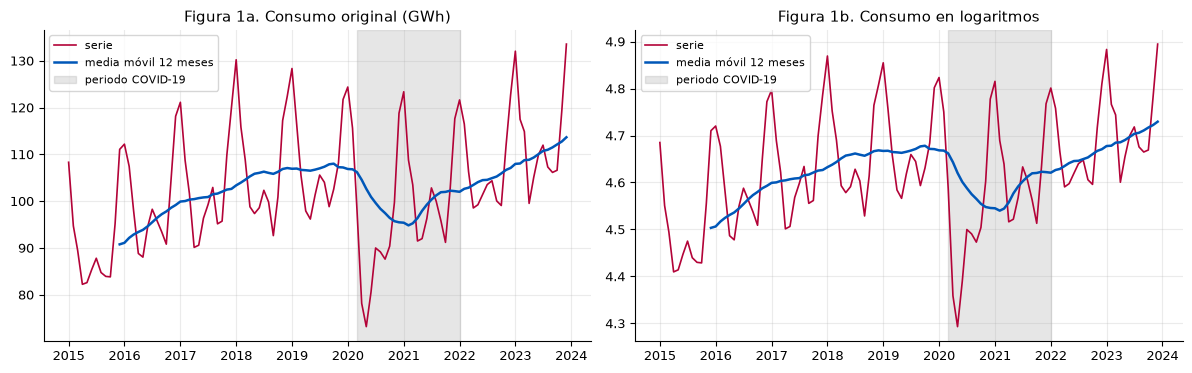

Lambda de Box-Cox (MLE)         : 0.11
Elasticidad (std anual vs media): 0.31  (0 = aditivo puro, 1 = multiplicativo puro)


In [5]:
# ============================================================
# 3.1 ¿Logaritmo o serie original?
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, serie, tit in zip(axes, [y_aj, ly],
                          ["Figura 1a. Consumo original (GWh)", "Figura 1b. Consumo en logaritmos"]):
    ax.plot(serie, color=ROJO, lw=1.2, label="serie")
    ax.plot(serie.rolling(12).mean(), color=AZUL, lw=1.8, label="media móvil 12 meses")
    ax.axvspan(COVID_INI, COVID_FIN, color=GRIS, alpha=0.25, label="periodo COVID-19")
    ax.set_title(tit); ax.legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

# Box-Cox: lambda por máxima verosimilitud (sobre la serie de trabajo)
lam = float(stats.boxcox_normmax(y_aj.values, method="mle"))

# Elasticidad de la variabilidad anual respecto del nivel anual (sin 2020-2021, afectados por el COVID)
anual = y_aj.groupby(y_aj.index.year).agg(["mean", "std"]).drop(index=[2020, 2021])
elasticidad = float(np.polyfit(np.log(anual["mean"]), np.log(anual["std"]), 1)[0])

print(f"Lambda de Box-Cox (MLE)         : {lam:.2f}")
print(f"Elasticidad (std anual vs media): {elasticidad:.2f}  (0 = aditivo puro, 1 = multiplicativo puro)")

In [6]:
# ============================================================
# 3.1 (cont.) Decisión sobre la transformación
# ============================================================
if lam < 0.5:
    frase_lam = (f"El λ de Box-Cox es {c(lam)}, más cerca de 0 (logaritmo) que de 1 (sin transformar), "
                 "lo que respalda usar logaritmo.")
else:
    frase_lam = (f"El λ de Box-Cox es {c(lam)}, más cerca de 1 que de 0, así que la evidencia estadística por sí sola "
                 "no exige logaritmo; lo mantengo igualmente por las razones de interpretación y de coherencia con la Sumativa 1.")

display(Markdown(f"""
**Decisión 1 — Transformación.**

| Elemento | Detalle |
|---|---|
| **Qué decidí** | Trabajar con el **logaritmo natural** del consumo, `ly = log(consumo)`. |
| **Evidencia** | {frase_lam} La elasticidad entre variabilidad y nivel es {c(elasticidad)}, es decir, la variabilidad sube con el nivel pero menos que proporcionalmente. |
| **Alternativa descartada** | Modelar el consumo en GWh sin transformar. Habría funcionado, pero la estacionalidad y el efecto del COVID quedarían en GWh y no en porcentaje. |
| **Consecuencias** | Las diferencias del logaritmo se leen como variaciones porcentuales y los pronósticos se devuelven a GWh con la exponencial. |
"""))


**Decisión 1 — Transformación.**

| Elemento | Detalle |
|---|---|
| **Qué decidí** | Trabajar con el **logaritmo natural** del consumo, `ly = log(consumo)`. |
| **Evidencia** | El λ de Box-Cox es 0,11, más cerca de 0 (logaritmo) que de 1 (sin transformar), lo que respalda usar logaritmo. La elasticidad entre variabilidad y nivel es 0,31, es decir, la variabilidad sube con el nivel pero menos que proporcionalmente. |
| **Alternativa descartada** | Modelar el consumo en GWh sin transformar. Habría funcionado, pero la estacionalidad y el efecto del COVID quedarían en GWh y no en porcentaje. |
| **Consecuencias** | Las diferencias del logaritmo se leen como variaciones porcentuales y los pronósticos se devuelven a GWh con la exponencial. |


## 3.2 Tests de raíz unitaria (ADF y KPSS)

El ADF (Dickey y Fuller, 1979) tiene como H₀ la existencia de raíz unitaria y el KPSS (Kwiatkowski et al., 1992), la estacionariedad; por eso se leen juntos. Los aplico a la serie en nivel y a tres diferenciaciones, y clasifico cada una así:

- **Estacionaria:** ADF rechaza (p < 0,05) y KPSS no rechaza (p ≥ 0,05).
- **No estacionaria:** ADF no rechaza y KPSS rechaza.
- **Discrepante o no concluyente:** cualquier otra combinación.

En el nivel uso constante y tendencia (`ct`); en las series diferenciadas, solo constante (`c`). Los rezagos del ADF se eligen por AIC. Agrego dos señales: la desviación estándar (si sube al diferenciar, hay sobrediferenciación) y la ACF en el rezago 12 (si es alta y positiva, queda estacionalidad).

In [7]:
# ============================================================
# 3.2 Tests ADF y KPSS sobre las combinaciones de diferenciación
# ============================================================
def evaluar(x, reg):
    """ADF + KPSS + señales auxiliares para una serie x."""
    x = x.dropna()
    a_est, a_p, a_lag = adfuller(x, regression=reg, autolag="AIC")[:3]
    k_est, k_p, k_lag = kpss(x, regression=reg, nlags="auto")[:3]
    if a_p < 0.05 and k_p >= 0.05:
        veredicto = "Estacionaria"
    elif a_p >= 0.05 and k_p < 0.05:
        veredicto = "No estacionaria"
    else:
        veredicto = "Discrepante / no concluyente"
    return {"n": len(x), "ADF estad.": a_est, "ADF p": a_p, "KPSS estad.": k_est, "KPSS p": k_p,
            "desv. est.": float(x.std()), "ACF(12)": float(acf(x, nlags=S)[S]), "veredicto": veredicto}

def tabla_pruebas(serie_log):
    """Evalúa (d, D) en {0,1} x {0,1} sobre una serie en logaritmos."""
    opc = {(0, 0): serie_log,
           (1, 0): serie_log.diff(),
           (0, 1): serie_log.diff(S),
           (1, 1): serie_log.diff().diff(S)}
    filas = {k: evaluar(v, "ct" if k == (0, 0) else "c") for k, v in opc.items()}
    return opc, filas

nombres = {(0, 0): "Nivel (log)", (1, 0): "d=1", (0, 1): "D=1 (lag 12)", (1, 1): "d=1 y D=1"}
opciones, pruebas = tabla_pruebas(ly)

tab_pruebas = pd.DataFrame(pruebas).T
tab_pruebas.index = [nombres[k] for k in pruebas]
# Referencia: la serie original sin logaritmo
ref = evaluar(y_aj, "ct")
tab_pruebas.loc["Nivel (original, GWh)"] = ref
tab_pruebas = tab_pruebas.loc[["Nivel (original, GWh)"] + [nombres[k] for k in pruebas]]
print("Tabla 1. Tests de raíz unitaria según el nivel de diferenciación (muestra 2015-2023)")
display(tab_pruebas.drop(columns="n").astype({"ADF estad.": float, "ADF p": float, "KPSS estad.": float,
                                              "KPSS p": float, "desv. est.": float, "ACF(12)": float}).round(3))
print("Nota: el p-valor de KPSS se reporta truncado entre 0,01 y 0,10 (límites de las tablas del test).")

Tabla 1. Tests de raíz unitaria según el nivel de diferenciación (muestra 2015-2023)


,ADF estad.,ADF p,KPSS estad.,KPSS p,desv. est.,ACF(12),veredicto
"Nivel (original, GWh)",-1.817,0.697,0.091,0.1,12.498,0.651,Discrepante / no concluyente
Nivel (log),-2.087,0.553,0.095,0.1,0.122,0.618,Discrepante / no concluyente
d=1,-2.908,0.044,0.040,0.1,0.080,0.744,Estacionaria
D=1 (lag 12),-2.846,0.052,0.192,0.1,0.081,-0.203,Discrepante / no concluyente
d=1 y D=1,-10.451,0.000,0.041,0.1,0.046,-0.330,Estacionaria


Nota: el p-valor de KPSS se reporta truncado entre 0,01 y 0,10 (límites de las tablas del test).


## 3.3 Decisión sobre los órdenes de diferenciación

Fijo la regla antes de ver la decisión: elijo la **menor diferenciación**, en el orden (0, 0), (0, 1), (1, 0) y (1, 1), que cumpla dos condiciones:

1. Veredicto **estacionaria** (ADF rechaza y KPSS no rechaza).
2. ACF en el rezago 12 menor que 0,5, es decir, sin estacionalidad fuerte remanente.

Si ninguna cumple, uso (1, 1), lo anticipado en la Sumativa 1. Como el COVID-19 puede distorsionar los tests, repito la regla con los años 2015-2019.

In [8]:
# ============================================================
# 3.3 Regla de decisión y prueba de robustez (solo años previos al COVID-19)
# ============================================================
ORDEN_PRUEBA = [(0, 0), (0, 1), (1, 0), (1, 1)]

def elegir(filas):
    for k in ORDEN_PRUEBA:
        if filas[k]["veredicto"] == "Estacionaria" and filas[k]["ACF(12)"] < 0.5:
            return k, True
    return (1, 1), False

(d_sel, D_sel), cumple_regla = elegir(pruebas)

# Robustez: misma regla con la muestra 2015-01 a 2019-12 (antes del COVID-19)
_, pruebas_pre = tabla_pruebas(ly.loc[:"2019-12-01"])
(d_pre, D_pre), cumple_pre = elegir(pruebas_pre)

tab_rob = pd.DataFrame(pruebas_pre).T
tab_rob.index = [nombres[k] for k in pruebas_pre]
print("Tabla 2. Robustez: tests con la muestra 2015-2019 (sin COVID-19)")
display(tab_rob.drop(columns="n").astype({"ADF estad.": float, "ADF p": float, "KPSS estad.": float,
                                          "KPSS p": float, "desv. est.": float, "ACF(12)": float}).round(3))

# Texto con la decisión y su evidencia
f_sel = pruebas[(d_sel, D_sel)]
sd_cmp = {nombres[k]: pruebas[k]["desv. est."] for k in pruebas}
sobre_dif = ""
if (d_sel, D_sel) == (1, 1):
    # Se compara con las alternativas con una sola diferenciación para ver si hay sobrediferenciación
    sobre_dif = (f" La desviación estándar con d=1 y D=1 es {c(f_sel['desv. est.'], 4)}, frente a "
                 f"{c(pruebas[(0, 1)]['desv. est.'], 4)} con solo D=1 y {c(pruebas[(1, 0)]['desv. est.'], 4)} con solo d=1.")
razon_regla = ("cumple las dos condiciones de la regla" if cumple_regla else
               "ninguna combinación cumplió la regla, por lo que se aplicó la opción por defecto (1, 1)")
coincide = "coincide" if (d_pre, D_pre) == (d_sel, D_sel) else "no coincide"

display(Markdown(f"""
**Decisión 2 — Diferenciación.**

| Elemento | Detalle |
|---|---|
| **Qué decidí** | Usar **d = {d_sel}** (diferencia regular) y **D = {D_sel}** (diferencia estacional con s = {S}). Esta combinación {razon_regla}. |
| **Evidencia** | Con (d={d_sel}, D={D_sel}) el ADF da {p_(f_sel['ADF p'])} y el KPSS {p_(f_sel['KPSS p'])}, con veredicto **{f_sel['veredicto'].lower()}**; la autocorrelación en el rezago 12 es {c(f_sel['ACF(12)'])}.{sobre_dif} En el nivel (log), el ADF da {p_(pruebas[(0, 0)]['ADF p'])} y el KPSS {p_(pruebas[(0, 0)]['KPSS p'])}, con veredicto *{pruebas[(0, 0)]['veredicto'].lower()}*, y su ACF(12) es {c(pruebas[(0, 0)]['ACF(12)'])}. |
| **Robustez** | Con los datos de 2015-2019 la regla elige (d={d_pre}, D={D_pre}), lo que {coincide} con la decisión de la muestra completa. |
| **Alternativa descartada** | Menos diferenciación deja tendencia o estacionalidad; más diferenciación infla la varianza e introduce autocorrelación artificial (sobrediferenciación). |
| **Consecuencias** | Los modelos candidatos usarán d = {d_sel} y D = {D_sel}, con los efectos del COVID-19 como regresores. La diferenciación consume las primeras {d_sel + D_sel * S} observaciones de la serie. |
"""))

Tabla 2. Robustez: tests con la muestra 2015-2019 (sin COVID-19)


,ADF estad.,ADF p,KPSS estad.,KPSS p,desv. est.,ACF(12),veredicto
Nivel (log),-1.044,0.938,0.054,0.10,0.114,0.628,Discrepante / no concluyente
d=1,-2.476,0.121,0.059,0.10,0.076,0.706,Discrepante / no concluyente
D=1 (lag 12),-3.154,0.023,0.811,0.01,0.045,-0.203,Discrepante / no concluyente
d=1 y D=1,-9.255,0.000,0.126,0.10,0.039,-0.237,Estacionaria



**Decisión 2 — Diferenciación.**

| Elemento | Detalle |
|---|---|
| **Qué decidí** | Usar **d = 1** (diferencia regular) y **D = 1** (diferencia estacional con s = 12). Esta combinación cumple las dos condiciones de la regla. |
| **Evidencia** | Con (d=1, D=1) el ADF da p < 0,001 y el KPSS p = 0,100, con veredicto **estacionaria**; la autocorrelación en el rezago 12 es -0,33. La desviación estándar con d=1 y D=1 es 0,0465, frente a 0,0806 con solo D=1 y 0,0800 con solo d=1. En el nivel (log), el ADF da p = 0,553 y el KPSS p = 0,100, con veredicto *discrepante / no concluyente*, y su ACF(12) es 0,62. |
| **Robustez** | Con los datos de 2015-2019 la regla elige (d=1, D=1), lo que coincide con la decisión de la muestra completa. |
| **Alternativa descartada** | Menos diferenciación deja tendencia o estacionalidad; más diferenciación infla la varianza e introduce autocorrelación artificial (sobrediferenciación). |
| **Consecuencias** | Los modelos candidatos usarán d = 1 y D = 1, con los efectos del COVID-19 como regresores. La diferenciación consume las primeras 13 observaciones de la serie. |


## 3.4 Verificación de la estacionariedad resultante

Reviso que la serie diferenciada tenga media y variabilidad estables mediante su media y su desviación móviles de 12 meses. El COVID-19 es el único tramo en que se espera un comportamiento distinto.

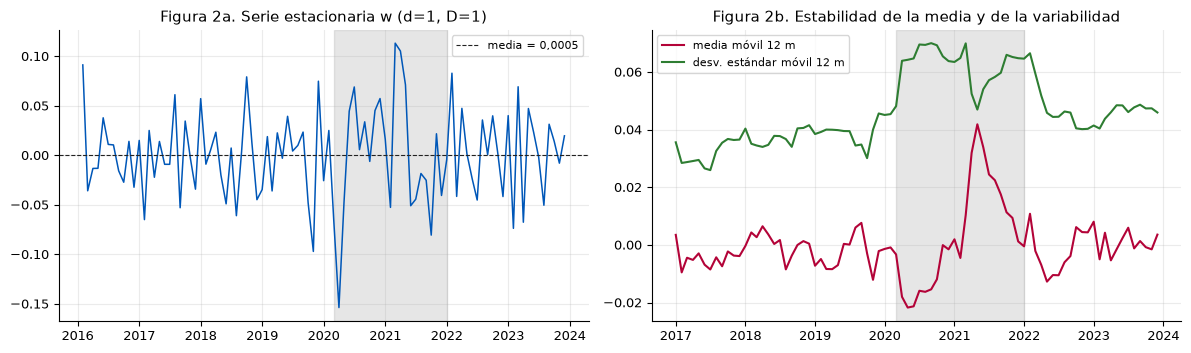


**Lectura (Figuras 2a y 2b).** La serie diferenciada oscila alrededor de 0,001 (media de toda la muestra), sin la tendencia ni los ciclos anuales que tenía el nivel. Los tests confirman el resultado: ADF con p < 0,001 y KPSS con p = 0,100 (estacionaria).
La desviación estándar de w es 0,0399 fuera del periodo COVID-19 y 0,0638 dentro de él. Dentro del periodo COVID-19 la variabilidad es mayor, y por eso incorporo el COVID-19 como regresor en los modelos (sección 4).
**Conclusión de la sección 3:** la serie se vuelve estacionaria con log + d = 1 + D = 1, y esa es la base para identificar los modelos.


In [9]:
# ============================================================
# 3.4 Verificación: serie diferenciada elegida (w), media y desviación móviles
# ============================================================
w = opciones[(d_sel, D_sel)].dropna()
w.name = "w"

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].plot(w, color=AZUL, lw=1.1)
axes[0].axhline(w.mean(), color=NEGRO, lw=0.8, ls="--", label=f"media = {c(w.mean(), 4)}")
axes[0].axvspan(COVID_INI, COVID_FIN, color=GRIS, alpha=0.25)
axes[0].set_title(f"Figura 2a. Serie estacionaria w (d={d_sel}, D={D_sel})"); axes[0].legend(fontsize=8)
axes[1].plot(w.rolling(12).mean(), color=ROJO, label="media móvil 12 m")
axes[1].plot(w.rolling(12).std(), color=VERDE, label="desv. estándar móvil 12 m")
axes[1].axvspan(COVID_INI, COVID_FIN, color=GRIS, alpha=0.25)
axes[1].set_title("Figura 2b. Estabilidad de la media y de la variabilidad"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

# Comparación de la variabilidad dentro y fuera del COVID-19
en_cov = (w.index >= COVID_INI) & (w.index <= COVID_FIN)
sd_fuera, sd_dentro = float(w[~en_cov].std()), float(w[en_cov].std())
p_adf, p_kp = pruebas[(d_sel, D_sel)]["ADF p"], pruebas[(d_sel, D_sel)]["KPSS p"]

display(Markdown(f"""
**Lectura (Figuras 2a y 2b).** La serie diferenciada oscila alrededor de {c(w.mean(), 3)} (media de toda la muestra), sin la tendencia ni los ciclos anuales que tenía el nivel. Los tests confirman el resultado: ADF con {p_(p_adf)} y KPSS con {p_(p_kp)} ({pruebas[(d_sel, D_sel)]['veredicto'].lower()}).
La desviación estándar de w es {c(sd_fuera, 4)} fuera del periodo COVID-19 y {c(sd_dentro, 4)} dentro de él. {'Dentro del periodo COVID-19 la variabilidad es mayor, y por eso incorporo el COVID-19 como regresor en los modelos (sección 4).' if sd_dentro > sd_fuera else 'La variabilidad es parecida dentro y fuera del COVID-19.'}
**Conclusión de la sección 3:** la serie se vuelve estacionaria con log + d = {d_sel} + D = {D_sel}, y esa es la base para identificar los modelos.
"""))

> **Interpretación del autor — Sección 3 (estacionariedad).** *(Escribir con mis propias palabras, de 4 a 6 líneas. Este espacio es parte de mi trabajo personal y no se genera con código ni con IA.)*
>
> - ¿Por qué ADF y KPSS se usan juntos y qué significaría que se contradijeran en mi serie?
> - ¿Qué diferencia vi entre la serie en nivel y la serie diferenciada, y qué hizo cada diferencia (d y D)?
> - ¿Cómo pudo influir el COVID-19 en los tests y por qué igual me quedé con esa decisión?
>
> **[COMPLETAR]**

# 4. Identificación y estimación de modelos (AR, MA, ARMA, ARIMA, SARIMA)

Con la serie estacionaria, propongo los órdenes p, q, P y Q a partir de la ACF y la PACF, y estimo los modelos por máxima verosimilitud (Seabold y Perktold, 2010). La notación SARIMA(p, d, q)(P, D, Q)ₛ incluye términos AR (p) y MA (q), la diferenciación regular (d) y sus equivalentes estacionales (P, D, Q); AR, MA, ARMA y ARIMA son casos particulares.

## 4.1 Lectura de la ACF y la PACF

Reglas de lectura (Box et al., 2015; Hyndman y Athanasopoulos, 2021):

| Si en la serie estacionaria se ve… | entonces sugiere… |
|---|---|
| PACF con corte claro después del rezago *p* y ACF que decae | un componente **AR(p)** |
| ACF con corte claro después del rezago *q* y PACF que decae | un componente **MA(q)** |
| Ambas decaen sin cortar | un modelo mixto **ARMA(p, q)** |
| Pico significativo en el rezago 12 de la ACF | un término **MA estacional (Q = 1)** |
| Pico significativo en el rezago 12 de la PACF (sin pico en la ACF) | un término **AR estacional (P = 1)** |

La banda de significancia al 95 % es ±1,96/√n; miro hasta 24 rezagos (dos ciclos anuales).

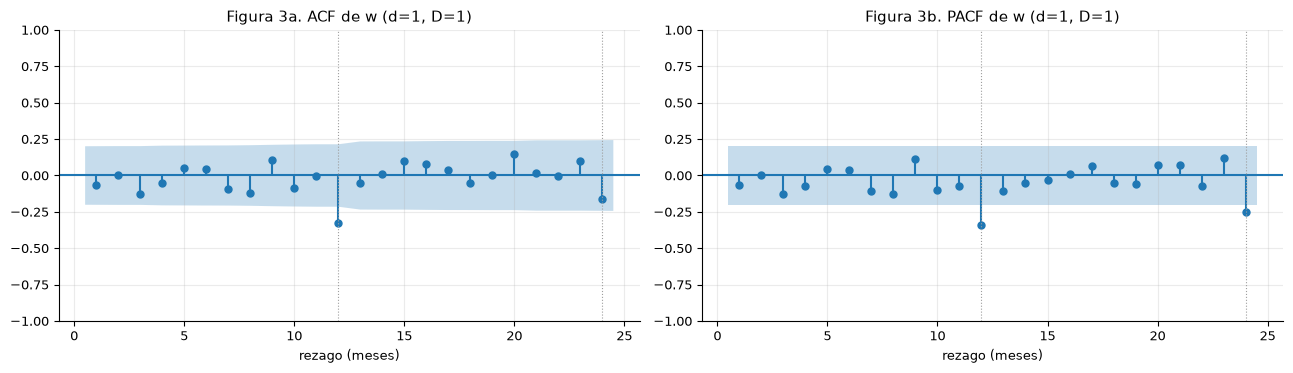

n = 95; banda 95% = ±0.201
Rezagos ACF significativos : [12]
Rezagos PACF significativos: [12, 24]


In [10]:
# ============================================================
# 4.1 ACF y PACF de la serie estacionaria w
# ============================================================
NL = 24
r_w = acf(w, nlags=NL)
p_w = pacf(w, nlags=NL, method="ywm")
banda = 1.96 / np.sqrt(len(w))
sig_acf = [k for k in range(1, NL + 1) if abs(r_w[k]) > banda]
sig_pacf = [k for k in range(1, NL + 1) if abs(p_w[k]) > banda]

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
plot_acf(w, lags=NL, ax=axes[0], zero=False, title=f"Figura 3a. ACF de w (d={d_sel}, D={D_sel})")
plot_pacf(w, lags=NL, ax=axes[1], zero=False, method="ywm", title=f"Figura 3b. PACF de w (d={d_sel}, D={D_sel})")
for ax in axes:
    ax.set_xlabel("rezago (meses)")
    for k in (12, 24):
        ax.axvline(k, color=GRIS, ls=":", lw=0.8)
plt.tight_layout(); plt.show()

print(f"n = {len(w)}; banda 95% = ±{banda:.3f}")
print("Rezagos ACF significativos :", sig_acf)
print("Rezagos PACF significativos:", sig_pacf)

In [11]:
# ============================================================
# 4.1 (cont.) Órdenes sugeridos por la evidencia (regla explícita)
# ============================================================
def mayor_corto(sig, tope=3):
    """Mayor rezago significativo entre 1 y `tope` (0 si no hay)."""
    cortos = [k for k in sig if k <= tope]
    return max(cortos) if cortos else 0

p_sug = min(mayor_corto(sig_pacf), 2)            # AR no estacional (se limita a 2 para no sobreajustar)
q_sug = min(mayor_corto(sig_acf), 2)             # MA no estacional
Q_sug = int(S in sig_acf)                         # MA estacional si la ACF es significativa en 12
P_sug = int((S in sig_pacf) and (S not in sig_acf))   # AR estacional si solo la PACF lo es

pico12_acf = r_w[S]; pico12_pacf = p_w[S]
display(Markdown(f"""
**Lectura (Figuras 3a y 3b).**

- **Parte no estacional.** Rezagos significativos de la ACF: {sig_acf if sig_acf else 'ninguno'}. Rezagos significativos de la PACF: {sig_pacf if sig_pacf else 'ninguno'}. En los primeros tres rezagos, el último rezago significativo de la PACF es {mayor_corto(sig_pacf)} y el de la ACF es {mayor_corto(sig_acf)}, lo que sugiere p = {p_sug} y q = {q_sug}.
- **Parte estacional.** En el rezago 12 la ACF vale {c(pico12_acf)} ({'significativa' if S in sig_acf else 'no significativa'}) y la PACF vale {c(pico12_pacf)} ({'significativa' if S in sig_pacf else 'no significativa'}). Eso sugiere P = {P_sug} y Q = {Q_sug}.
- **Resumen:** la evidencia apunta a un **SARIMA({p_sug},{d_sel},{q_sug})({P_sug},{D_sel},{Q_sug})₁₂** como candidato principal. Como la lectura de correlogramas con pocos datos es incierta (n = {len(w)}), pruebo también modelos vecinos y los modelos de referencia de cada familia.
"""))


**Lectura (Figuras 3a y 3b).**

- **Parte no estacional.** Rezagos significativos de la ACF: [12]. Rezagos significativos de la PACF: [12, 24]. En los primeros tres rezagos, el último rezago significativo de la PACF es 0 y el de la ACF es 0, lo que sugiere p = 0 y q = 0.
- **Parte estacional.** En el rezago 12 la ACF vale -0,33 (significativa) y la PACF vale -0,34 (significativa). Eso sugiere P = 0 y Q = 1.
- **Resumen:** la evidencia apunta a un **SARIMA(0,1,0)(0,1,1)₁₂** como candidato principal. Como la lectura de correlogramas con pocos datos es incierta (n = 95), pruebo también modelos vecinos y los modelos de referencia de cada familia.


## 4.2 Modelos candidatos

Incluyo todas las familias que pide la evaluación, y todos los candidatos llevan los regresores `covid` y `covid_pico`:

- **AR, MA y ARMA:** sobre la serie con los d y D elegidos, sin parte estacional propia.
- **ARIMA sin estacionalidad (D = 0):** referencia para medir cuánto aporta la parte estacional.
- **SARIMA:** el sugerido por la ACF/PACF, el «modelo de líneas aéreas» SARIMA(0,d,1)(0,D,1)₁₂ y variantes vecinas.

Término determinista: constante si d + D = 0, tendencia lineal (*drift*) si d + D = 1 y ninguno si d + D = 2.

In [12]:
# ============================================================
# 4.2 Definición de los modelos candidatos
# ============================================================
# Cada candidato: (familia, origen, p, d, q, P, D, Q)
d, D = d_sel, D_sel
d_arima = max(d, 1)       # el ARIMA de referencia no tiene parte estacional, así que necesita al menos d = 1

candidatos = [
    ("AR",     "clásico",  1, d, 0, 0, D, 0),
    ("AR",     "clásico",  2, d, 0, 0, D, 0),
    ("MA",     "clásico",  0, d, 1, 0, D, 0),
    ("MA",     "clásico",  0, d, 2, 0, D, 0),
    ("ARMA",   "clásico",  1, d, 1, 0, D, 0),
    ("ARMA",   "clásico",  2, d, 1, 0, D, 0),
    ("ARIMA",  "referencia sin estacionalidad", 1, d_arima, 1, 0, 0, 0),
    ("ARIMA",  "referencia sin estacionalidad", 2, d_arima, 1, 0, 0, 0),
    ("SARIMA", "clásico",  1, d, 0, 1, D, 0),
    ("SARIMA", "clásico",  0, d, 1, 0, D, 1),       # "airline"
    ("SARIMA", "clásico",  1, d, 0, 0, D, 1),
    ("SARIMA", "clásico",  1, d, 1, 0, D, 1),
    ("SARIMA", "clásico",  2, d, 0, 0, D, 1),
    ("SARIMA", "clásico",  1, d, 1, 1, D, 1),
    ("SARIMA", "clásico",  2, d, 1, 0, D, 1),
]
# Candidato sugerido por la ACF/PACF: si ya estaba en la lista solo se etiqueta; si no, se agrega
sug = ("SARIMA", "sugerido por ACF/PACF", p_sug, d, q_sug, P_sug, D, Q_sug)
if sug[2:] in [c_[2:] for c_ in candidatos]:
    candidatos = [(c_[0], "sugerido por ACF/PACF" if c_[2:] == sug[2:] else c_[1], *c_[2:]) for c_ in candidatos]
else:
    candidatos.insert(8, sug)

def nombre_modelo(fam, p, d_, q, P, D_, Q):
    """Nombre legible del modelo según su familia."""
    if fam == "AR":
        return f"AR({p}) [d={d_}, D={D_}]"
    if fam == "MA":
        return f"MA({q}) [d={d_}, D={D_}]"
    if fam == "ARMA":
        return f"ARMA({p},{q}) [d={d_}, D={D_}]"
    if fam == "ARIMA":
        return f"ARIMA({p},{d_},{q})"
    return f"SARIMA({p},{d_},{q})({P},{D_},{Q})[{S}]"

NOMBRES = {c_[2:]: nombre_modelo(c_[0], *c_[2:]) for c_ in candidatos}   # (p,d,q,P,D,Q) -> nombre

tab_cand = pd.DataFrame(
    [{"modelo": NOMBRES[c_[2:]], "familia": c_[0], "origen": c_[1],
      "p": c_[2], "d": c_[3], "q": c_[4], "P": c_[5], "D": c_[6], "Q": c_[7]} for c_ in candidatos]
).set_index("modelo")
por_familia = ", ".join(f"{k} {v}" for k, v in tab_cand["familia"].value_counts().items())
print(f"{len(tab_cand)} modelos candidatos ({por_familia}). Sugerido por ACF/PACF: {NOMBRES[sug[2:]]}")

16 modelos candidatos (SARIMA 8, AR 2, MA 2, ARMA 2, ARIMA 2). Sugerido por ACF/PACF: SARIMA(0,1,0)(0,1,1)[12]


## 4.3 Estimación

Estimo cada candidato con `statsmodels` (máxima verosimilitud con filtro de Kalman, hasta 1.000 iteraciones del optimizador) dos veces: con 2015-2022, para pronosticar 2023, y con 2015-2023, para AIC, BIC y residuos. Registro si el optimizador **convergió** en ambas estimaciones y cuántos parámetros ARMA no son significativos (p ≥ 0,05), como señal de sobreparametrización. Un modelo que no converge no es elegible en la sección 5.

In [13]:
# ============================================================
# 4.3 Estimación de todos los candidatos
# ============================================================
def tendencia(d_, D_):
    """Término determinista compatible con el orden de diferenciación."""
    k = d_ + D_
    return "c" if k == 0 else ("t" if k == 1 else "n")

def ajustar(serie, exog, spec):
    """Ajusta un modelo ARIMA/SARIMA con regresores opcionales. spec = (p, d, q, P, D, Q)."""
    p, d_, q, P, D_, Q = spec
    est = (P, D_, Q, S) if (P or D_ or Q) else (0, 0, 0, 0)
    modelo = ARIMA(serie, exog=exog, order=(p, d_, q), seasonal_order=est, trend=tendencia(d_, D_))
    return modelo.fit(method_kwargs={"maxiter": 1000})

def pronosticar(res, pasos, exog_f):
    """Pronóstico en GWh (se invierte el logaritmo) con su intervalo de 95 %."""
    fc = res.get_forecast(steps=pasos, exog=exog_f)
    ic = fc.conf_int(alpha=0.05)
    ic = np.asarray(ic)
    return np.exp(np.asarray(fc.predicted_mean)), np.exp(ic[:, 0]), np.exp(ic[:, 1])

ent_val = ly.loc[:"2022-12-01"]                      # entrenamiento de la validación
X_ent_val = X.loc[ent_val.index]
idx_val = ly.loc["2023-01-01":].index                # 2023
X_val = X.loc[idx_val]

resultados = {}
filas = []
for fam, origen, p, d_, q, P, D_, Q in candidatos:
    spec = (p, d_, q, P, D_, Q)
    nom = NOMBRES[spec]
    try:
        r_full = ajustar(ly, X, spec)                # 2015-2023 (AIC, BIC, residuos)
        r_val = ajustar(ent_val, X_ent_val, spec)    # 2015-2022 (pronóstico 2023)
        pred_val, _, _ = pronosticar(r_val, 12, X_val)
    except Exception as e:                           # un modelo que no converge se informa y se descarta
        print(f"[aviso] {nom} no se pudo estimar: {type(e).__name__}")
        continue
    conv = bool(r_full.mle_retvals.get("converged", True) and r_val.mle_retvals.get("converged", True))
    pv_arma = r_full.pvalues[[n for n in r_full.pvalues.index if n.startswith(("ar.", "ma."))]]
    resultados[nom] = {"spec": spec, "full": r_full, "val": r_val,
                       "pred_val": pd.Series(pred_val, index=idx_val), "k_arma": len(pv_arma), "conv": conv}
    filas.append({"modelo": nom, "familia": fam, "p": p, "d": d_, "q": q, "P": P, "D": D_, "Q": Q,
                  "k": len(r_full.params), "parámetros ARMA": len(pv_arma),
                  "ARMA no signif.": int((pv_arma >= 0.05).sum()), "convergió": "Sí" if conv else "No",
                  "logL": r_full.llf, "AIC": r_full.aic, "BIC": r_full.bic})

tabla = pd.DataFrame(filas).set_index("modelo")
print(f"Tabla 3. Estimación de {len(tabla)} modelos (muestra 2015-2023, n = {len(ly)}); AIC y BIC en la Tabla 6")
display(tabla[["k", "ARMA no signif.", "convergió", "logL"]].round(2))
no_conv = [n for n, r in resultados.items() if not r["conv"]]
print("Sin convergencia en alguna estimación (no elegibles):", ", ".join(no_conv) if no_conv else "ninguno")

Tabla 3. Estimación de 16 modelos (muestra 2015-2023, n = 108); AIC y BIC en la Tabla 6


,k,ARMA no signif.,convergió,logL
modelo,,,,
"AR(1) [d=1, D=1]",4,0,Sí,179.72
"AR(2) [d=1, D=1]",5,1,Sí,179.85
"MA(1) [d=1, D=1]",4,0,Sí,180.03
"MA(2) [d=1, D=1]",5,1,Sí,180.03
"ARMA(1,1) [d=1, D=1]",5,2,Sí,180.03
"ARMA(2,1) [d=1, D=1]",6,0,Sí,182.09
"ARIMA(1,1,1)",6,2,Sí,135.88
"ARIMA(2,1,1)",7,0,Sí,155.74
"SARIMA(0,1,0)(0,1,1)[12]",4,1,Sí,190.01


Sin convergencia en alguna estimación (no elegibles): SARIMA(2,1,0)(0,1,1)[12]


In [14]:
# ============================================================
# 4.3 (cont.) Efecto estimado del COVID-19 en el modelo sugerido
# ============================================================
nom_ref = NOMBRES[(p_sug, d_sel, q_sug, P_sug, D_sel, Q_sug)]
r_ref = resultados[nom_ref]["full"]
coef = pd.DataFrame({"coeficiente": r_ref.params, "error estándar": r_ref.bse, "valor-p": r_ref.pvalues}).round(4)
print(f"Tabla 4. Coeficientes del modelo {nom_ref}")
display(coef)

b_cov, b_pico = r_ref.params["covid"], r_ref.params["covid_pico"]
neg_sig = (b_cov < 0 and b_pico < 0 and r_ref.pvalues["covid"] < 0.05 and r_ref.pvalues["covid_pico"] < 0.05)
cierre_covid = ("Ambos coeficientes son negativos y significativos, lo que concuerda con lo visto en la Sumativa 1: el consumo cayó con el COVID-19 y tocó fondo en el trimestre abril-junio de 2020."
                if neg_sig else
                "Al menos uno de los coeficientes no es significativo o no es negativo, es decir, la estimación del efecto del COVID-19 es imprecisa con estos datos (hay pocos meses afectados), aunque se mantiene en el modelo por la evidencia de la Sumativa 1.")
display(Markdown(f"""
**Lectura.** Se estimaron {len(tabla)} modelos. En el modelo {nom_ref}, el indicador del periodo COVID-19 vale {c(b_cov, 3)} (≈ {c(100 * (np.exp(b_cov) - 1), 1)} % sobre el nivel esperado, valor-p {pv(r_ref.pvalues['covid'])}) y el del mínimo de abril a junio de 2020 vale {c(b_pico, 3)} (≈ {c(100 * (np.exp(b_pico) - 1), 1)} % adicional, valor-p {pv(r_ref.pvalues['covid_pico'])}). {cierre_covid}
"""))

Tabla 4. Coeficientes del modelo SARIMA(0,1,0)(0,1,1)[12]


,coeficiente,error estándar,valor-p
covid,-0.0764,0.0391,0.0507
covid_pico,-0.1001,0.0230,0.0000
ma.S.L12,-0.9862,3.3910,0.7712
sigma2,0.0008,0.0028,0.7639



**Lectura.** Se estimaron 16 modelos. En el modelo SARIMA(0,1,0)(0,1,1)[12], el indicador del periodo COVID-19 vale -0,076 (≈ -7,4 % sobre el nivel esperado, valor-p 0,051) y el del mínimo de abril a junio de 2020 vale -0,100 (≈ -9,5 % adicional, valor-p < 0,001). Al menos uno de los coeficientes no es significativo o no es negativo, es decir, la estimación del efecto del COVID-19 es imprecisa con estos datos (hay pocos meses afectados), aunque se mantiene en el modelo por la evidencia de la Sumativa 1.


> **Interpretación del autor — Sección 4 (identificación y estimación).** *(Escribir con mis propias palabras, de 4 a 6 líneas. Este espacio es parte de mi trabajo personal y no se genera con código ni con IA.)*
>
> - ¿Qué vi en la ACF y la PACF (cortes, decaimientos, rezago 12) y qué modelos me sugirió cada patrón?
> - ¿Por qué incluí modelos de varias familias y qué espero aprender de compararlas?
> - ¿Qué dicen los coeficientes del COVID-19 y qué tan confiable me parece esa estimación?
>
> **[COMPLETAR]**

# 5. Selección y comparación de modelos

Comparo los modelos con (i) **AIC y BIC** (Akaike, 1974; Schwarz, 1978), que miden el ajuste penalizado por complejidad (menor es mejor), calculados con 2015-2023, y (ii) **métricas de pronóstico** para 2023, con modelos estimados hasta 2022. Las métricas se calculan en GWh:

- **RMSE** (penaliza más los errores grandes), **MAE** y **MAPE** (error porcentual).
- **MASE:** MAE dividido por el del ingenuo estacional en el entrenamiento (Hyndman y Koehler, 2006); un valor menor que 1 supera al ingenuo.

La referencia mínima es el **ingenuo estacional** (cada mes igual al mismo mes del año anterior). AIC y BIC solo se comparan entre modelos con los mismos d y D, porque la verosimilitud se calcula sobre observaciones distintas; por eso el ARIMA sin estacionalidad se juzga solo por pronóstico.

In [15]:
# ============================================================
# 5.1 Métricas de pronóstico de validación (2023) y del ingenuo estacional
# ============================================================
def metricas(real, pred, escala):
    real = np.asarray(real, float); pred = np.asarray(pred, float)
    err = pred - real
    return {"RMSE": float(np.sqrt(np.mean(err ** 2))),
            "MAE": float(np.mean(np.abs(err))),
            "MAPE": float(np.mean(np.abs(err) / real) * 100),
            "MASE": float(np.mean(np.abs(err)) / escala),
            "sesgo %": float(np.mean(err) / np.mean(real) * 100)}

real_val = y_aj.loc["2023-01-01":"2023-12-01"]
escala_val = float(y_aj.loc[:"2022-12-01"].diff(S).dropna().abs().mean())     # MAE del ingenuo estacional en entrenamiento
naive_val = pd.Series(y_aj.loc["2022-01-01":"2022-12-01"].values, index=real_val.index)

m_val = pd.DataFrame({nom: metricas(real_val, r["pred_val"], escala_val) for nom, r in resultados.items()}).T
m_val.loc["Ingenuo estacional"] = metricas(real_val, naive_val, escala_val)
m_val.columns = [f"{k}_val" if k != "sesgo %" else "sesgo_val %" for k in m_val.columns]

tabla = tabla.join(m_val.drop(index="Ingenuo estacional"))
print(f"Escala del MASE (MAE del ingenuo estacional en 2015-2022) = {escala_val:.2f} GWh")

Escala del MASE (MAE del ingenuo estacional en 2015-2022) = 6.48 GWh


In [16]:
# ============================================================
# 5.2 Ranking de los modelos comparables y referencias
# ============================================================
tabla["comparable"] = (tabla["d"] == d_sel) & (tabla["D"] == D_sel)
cols_rank = ["AIC", "BIC", "RMSE_val", "MASE_val"]
tabla["puntaje"] = np.nan
tabla.loc[tabla["comparable"], "puntaje"] = tabla.loc[tabla["comparable"], cols_rank].rank().mean(axis=1)

ranking = (tabla[tabla["comparable"]]
           .sort_values(["puntaje", "BIC"])
           [["k", "AIC", "BIC", "RMSE_val", "MASE_val", "convergió", "puntaje"]])

cols_ref = ["RMSE_val", "MAPE_val", "MASE_val"]
fuera = pd.concat([tabla.loc[~tabla["comparable"], cols_ref], m_val.loc[["Ingenuo estacional"], cols_ref]])
print("Tabla 5. Referencias no comparables por AIC/BIC (otra diferenciación o pronóstico ingenuo): solo métricas de 2023")
display(fuera.round(3))

Tabla 5. Referencias no comparables por AIC/BIC (otra diferenciación o pronóstico ingenuo): solo métricas de 2023


,RMSE_val,MAPE_val,MASE_val
"ARIMA(1,1,1)",17.711,14.848,2.493
"ARIMA(2,1,1)",7.988,5.265,0.944
Ingenuo estacional,7.294,5.663,1.012


In [17]:
# ============================================================
# 5.3 Elección: mejor puntaje que además pase el test de Ljung-Box
# ============================================================
BURN = d_sel + D_sel * S                               # primeras observaciones afectadas por la diferenciación
orden_modelos = ranking.index.tolist()

filas_lb = []
seleccion = None
for nom in orden_modelos:
    r_ = resultados[nom]
    e_ = r_["full"].resid.iloc[BURN:]
    lb_ = acorr_ljungbox(e_, lags=[12, 24], model_df=r_["k_arma"], return_df=True)
    ok_ = bool((lb_["lb_pvalue"] > 0.05).all())
    conv_ = r_["conv"]
    filas_lb.append({"modelo": nom, "puntaje": ranking.loc[nom, "puntaje"],
                     "LB p (rezago 12)": float(lb_["lb_pvalue"].iloc[0]),
                     "LB p (rezago 24)": float(lb_["lb_pvalue"].iloc[1]),
                     "pasa Ljung-Box": ok_, "convergió": conv_})
    if ok_ and conv_ and seleccion is None:
        seleccion = nom
hay_modelo_valido = seleccion is not None
if seleccion is None:                                   # si ninguno pasa, se queda el de mejor puntaje
    seleccion = orden_modelos[0]

tab_lb = pd.DataFrame(filas_lb).set_index("modelo")
tab_rank = ranking.join(tab_lb[["LB p (rezago 12)", "LB p (rezago 24)"]])
print("Tabla 6. Ranking de los modelos comparables (puntaje = ranking promedio en AIC, BIC, RMSE y MASE; menor es mejor). "
      "Se elige el primero que converge y cuyos residuos pasan Ljung-Box (p > 0,05 en los rezagos 12 y 24).")
display(tab_rank.round(3))

mejor_rank = orden_modelos[0]
sel = resultados[seleccion]
spec_sel = sel["spec"]
res_sel = sel["full"]
fila_sel = tabla.loc[seleccion]
fila_naive = m_val.loc["Ingenuo estacional"]
mejora_rmse = 100 * (1 - fila_sel["RMSE_val"] / fila_naive["RMSE_val"])
dif_bic = float(fila_sel["BIC"] - ranking["BIC"].min())
dif_aic = float(fila_sel["AIC"] - ranking["AIC"].min())
arimas = tabla[tabla["familia"] == "ARIMA"]
if len(arimas):
    texto_alt = (f"El mejor ARIMA sin parte estacional (D = 0) tuvo RMSE de validación = {c(arimas['RMSE_val'].min())} GWh, frente a {c(fila_sel['RMSE_val'])} GWh del modelo elegido. "
                 f"Los otros {len(orden_modelos) - 1} candidatos comparables quedaron con un puntaje peor o no cumplieron la convergencia o Ljung-Box (Tabla 6).")
else:
    texto_alt = f"Los otros {len(orden_modelos) - 1} candidatos comparables quedaron con un puntaje peor o no cumplieron la convergencia o Ljung-Box (Tabla 6)."

display(Markdown(f"""
**Decisión 3 — Modelo final: {seleccion}.**

| Elemento | Detalle |
|---|---|
| **Qué decidí** | Elegir el modelo **{seleccion}** ({fila_sel['familia']}). |
| **Evidencia de información** | AIC = {c(fila_sel['AIC'])} y BIC = {c(fila_sel['BIC'])}. Está a {c(dif_aic)} puntos de AIC y a {c(dif_bic)} puntos de BIC del mejor valor de cada criterio entre los modelos comparables. |
| **Evidencia de pronóstico** | En la validación 2023 tiene RMSE = {c(fila_sel['RMSE_val'])} GWh, MAPE = {c(fila_sel['MAPE_val'])} % y MASE = {c(fila_sel['MASE_val'])}. El ingenuo estacional tuvo RMSE = {c(fila_naive['RMSE_val'])} GWh y MASE = {c(fila_naive['MASE_val'])}, así que el modelo {'reduce' if mejora_rmse > 0 else 'aumenta'} el RMSE en {c(abs(mejora_rmse), 1)} % respecto del ingenuo. |
| **Regla de selección** | Mejor puntaje promedio en AIC, BIC, RMSE y MASE entre los modelos comparables, con dos condiciones: que la estimación converja y que sus residuos pasen Ljung-Box. {'El mejor puntaje fue ' + mejor_rank + (' y cumple ambas condiciones.' if mejor_rank == seleccion else ', pero no cumple alguna de las condiciones, por eso se eligió el siguiente que sí las cumple.') if hay_modelo_valido else 'Ningún modelo cumplió ambas condiciones; se conserva el de mejor puntaje y se discute esta limitación en la sección 6.'} |
| **Alternativas descartadas** | {texto_alt} |
"""))

Tabla 6. Ranking de los modelos comparables (puntaje = ranking promedio en AIC, BIC, RMSE y MASE; menor es mejor). Se elige el primero que converge y cuyos residuos pasan Ljung-Box (p > 0,05 en los rezagos 12 y 24).


,k,AIC,BIC,RMSE_val,MASE_val,convergió,puntaje,LB p (rezago 12),LB p (rezago 24)
modelo,,,,,,,,,
"SARIMA(0,1,1)(0,1,1)[12]",5,-391.076,-378.307,5.752,0.808,Sí,1.50,0.497,0.242
"SARIMA(1,1,1)(0,1,1)[12]",6,-389.360,-374.037,5.697,0.799,Sí,1.75,0.418,0.211
"SARIMA(1,1,1)(1,1,1)[12]",7,-387.404,-369.527,5.779,0.812,Sí,4.00,0.337,0.169
"SARIMA(2,1,0)(0,1,1)[12]",6,-388.650,-373.326,6.087,0.862,No,4.25,0.429,0.264
"SARIMA(1,1,0)(0,1,1)[12]",5,-388.572,-375.803,6.296,0.899,Sí,4.50,0.283,0.065
"SARIMA(2,1,1)(0,1,1)[12]",7,-385.575,-367.697,5.791,0.814,Sí,5.00,0.213,0.058
"SARIMA(0,1,0)(0,1,1)[12]",4,-372.026,-361.810,7.335,1.072,Sí,8.00,0.004,0.000
"SARIMA(1,1,0)(1,1,0)[12]",5,-363.629,-350.860,7.220,1.009,Sí,8.00,0.284,0.006
"ARMA(2,1) [d=1, D=1]",6,-352.175,-336.852,7.093,0.999,Sí,9.25,0.017,0.010



**Decisión 3 — Modelo final: SARIMA(0,1,1)(0,1,1)[12].**

| Elemento | Detalle |
|---|---|
| **Qué decidí** | Elegir el modelo **SARIMA(0,1,1)(0,1,1)[12]** (SARIMA). |
| **Evidencia de información** | AIC = -391,08 y BIC = -378,31. Está a 0,00 puntos de AIC y a 0,00 puntos de BIC del mejor valor de cada criterio entre los modelos comparables. |
| **Evidencia de pronóstico** | En la validación 2023 tiene RMSE = 5,75 GWh, MAPE = 4,64 % y MASE = 0,81. El ingenuo estacional tuvo RMSE = 7,29 GWh y MASE = 1,01, así que el modelo reduce el RMSE en 21,1 % respecto del ingenuo. |
| **Regla de selección** | Mejor puntaje promedio en AIC, BIC, RMSE y MASE entre los modelos comparables, con dos condiciones: que la estimación converja y que sus residuos pasen Ljung-Box. El mejor puntaje fue SARIMA(0,1,1)(0,1,1)[12] y cumple ambas condiciones. |
| **Alternativas descartadas** | El mejor ARIMA sin parte estacional (D = 0) tuvo RMSE de validación = 7,99 GWh, frente a 5,75 GWh del modelo elegido. Los otros 13 candidatos comparables quedaron con un puntaje peor o no cumplieron la convergencia o Ljung-Box (Tabla 6). |


In [18]:
# ============================================================
# 5.4 Estimación del modelo final: coeficientes
# ============================================================
print(res_sel.summary().tables[1])


# Nota técnica: término MA estacional (dato, sin interpretación)
ma_est = [n for n in res_sel.params.index if n.startswith("ma.S.")]
if ma_est:
    n_ = ma_est[0]
    cerca = abs(res_sel.params[n_]) > 0.9
    display(Markdown(
        f"**Nota técnica.** El coeficiente MA estacional (`{n_}`) vale {c(res_sel.params[n_], 3)}, con error estándar "
        f"{c(res_sel.bse[n_], 3)} ({p_(res_sel.pvalues[n_])})."
        + (" Su valor absoluto está cerca de 1, la frontera de invertibilidad; en esa zona el error estándar asintótico "
           "es poco preciso, por lo que el valor-p debe leerse con cautela." if cerca else "")))

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
covid         -0.0750      0.023     -3.254      0.001      -0.120      -0.030
covid_pico    -0.1267      0.016     -8.018      0.000      -0.158      -0.096
ma.L1         -0.5007      0.091     -5.505      0.000      -0.679      -0.322
ma.S.L12      -0.9591      0.973     -0.986      0.324      -2.866       0.948
sigma2         0.0007      0.001      1.036      0.300      -0.001       0.002


**Nota técnica.** El coeficiente MA estacional (`ma.S.L12`) vale -0,959, con error estándar 0,973 (p = 0,324). Su valor absoluto está cerca de 1, la frontera de invertibilidad; en esa zona el error estándar asintótico es poco preciso, por lo que el valor-p debe leerse con cautela.

Tabla 7. Prueba final 2024 (GWh); escala MASE = 6.49 GWh


,RMSE,MAE,MAPE,MASE,sesgo %
"SARIMA(0,1,1)(0,1,1)[12]",4.442,3.540,2.884,0.546,-2.046
Ingenuo estacional,8.193,6.666,5.397,1.027,-5.321


Cobertura del intervalo de 95 %: 92 % de los 12 meses


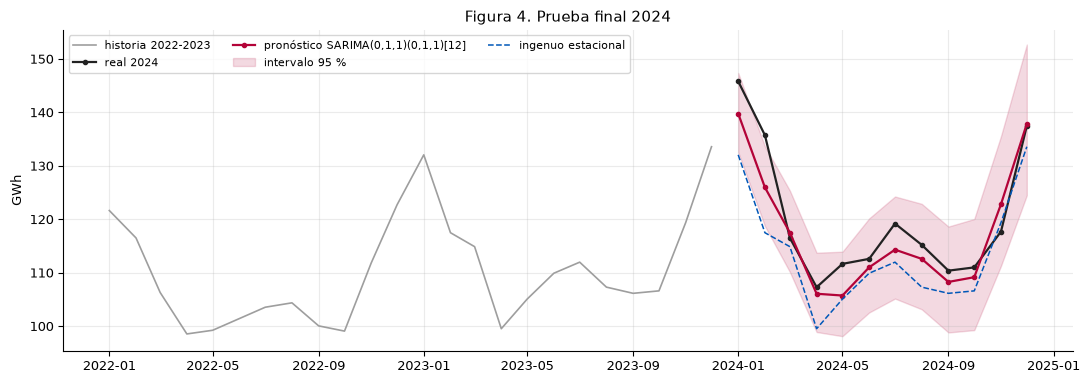


**Lectura (Tabla 7 y Figura 4).** En 2024 el modelo SARIMA(0,1,1)(0,1,1)[12] obtiene RMSE = 4,44 GWh, MAPE = 2,88 % y MASE = 0,55; el ingenuo estacional obtiene RMSE = 8,19 GWh y MASE = 1,03. El modelo **supera** al ingenuo estacional en RMSE. El sesgo promedio del pronóstico es -2,0 % (subestima el consumo), y el intervalo de 95 % contiene 92 % de los meses observados.
El sesgo es pequeño.


In [19]:
# ============================================================
# 5.5 Prueba final con el año 2024 (se usa una sola vez, con el modelo ya elegido)
# ============================================================
pred_t, lo_t, hi_t = pronosticar(res_sel, 12, X_prueba)   # res_sel está estimado con 2015-2023
pred_t = pd.Series(pred_t, index=prueba_2024.index)
lo_t = pd.Series(lo_t, index=prueba_2024.index); hi_t = pd.Series(hi_t, index=prueba_2024.index)
naive_t = pd.Series(y_aj.loc["2023-01-01":"2023-12-01"].values, index=prueba_2024.index)
escala_t = float(y_aj.diff(S).dropna().abs().mean())

m_test = pd.DataFrame({seleccion: metricas(prueba_2024, pred_t, escala_t),
                       "Ingenuo estacional": metricas(prueba_2024, naive_t, escala_t)}).T
cobertura = float(((prueba_2024 >= lo_t) & (prueba_2024 <= hi_t)).mean() * 100)
print(f"Tabla 7. Prueba final 2024 (GWh); escala MASE = {escala_t:.2f} GWh")
display(m_test.round(3))
print(f"Cobertura del intervalo de 95 %: {cobertura:.0f} % de los 12 meses")

fig, ax = plt.subplots(figsize=(11, 3.9))
ax.plot(y_aj.loc["2022-01-01":], color=GRIS, lw=1.2, label="historia 2022-2023")
ax.plot(prueba_2024, color=NEGRO, lw=1.6, marker="o", ms=3, label="real 2024")
ax.plot(pred_t, color=ROJO, lw=1.6, marker="o", ms=3, label=f"pronóstico {seleccion}")
ax.fill_between(pred_t.index, lo_t, hi_t, color=ROJO, alpha=0.15, label="intervalo 95 %")
ax.plot(naive_t, color=AZUL, lw=1.1, ls="--", label="ingenuo estacional")
ax.set_ylabel("GWh"); ax.legend(fontsize=8, ncol=3, loc="upper left")
ax.set_title("Figura 4. Prueba final 2024")
plt.tight_layout(); plt.show()

mejor = m_test.loc[seleccion, "RMSE"] < m_test.loc["Ingenuo estacional", "RMSE"]
sesgo_t = m_test.loc[seleccion, "sesgo %"]
display(Markdown(f"""
**Lectura (Tabla 7 y Figura 4).** En 2024 el modelo {seleccion} obtiene RMSE = {c(m_test.loc[seleccion, 'RMSE'])} GWh, MAPE = {c(m_test.loc[seleccion, 'MAPE'])} % y MASE = {c(m_test.loc[seleccion, 'MASE'])}; el ingenuo estacional obtiene RMSE = {c(m_test.loc['Ingenuo estacional', 'RMSE'])} GWh y MASE = {c(m_test.loc['Ingenuo estacional', 'MASE'])}. El modelo {'**supera**' if mejor else '**no supera**'} al ingenuo estacional en RMSE. El sesgo promedio del pronóstico es {c(sesgo_t, 1)} % ({'sobreestima' if sesgo_t > 0 else 'subestima'} el consumo), y el intervalo de 95 % contiene {c(cobertura, 0)} % de los meses observados.
{'El sesgo es pequeño.' if abs(sesgo_t) < 3 else 'El sesgo es relevante: en 2024 el consumo real se alejó de lo que extrapola el modelo, por ejemplo por un crecimiento distinto del que arrastra la tendencia estimada. Esto es una limitación de los modelos univariados, que solo proyectan el pasado.'}
"""))

> **Interpretación del autor — Sección 5 (selección y comparación).** *(Escribir con mis propias palabras, de 4 a 6 líneas. Este espacio es parte de mi trabajo personal y no se genera con código ni con IA.)*
>
> - ¿Por qué el modelo elegido es mejor que los demás según AIC, BIC y los errores de pronóstico, y dónde hubo conflicto entre criterios?
> - ¿Qué significa para el negocio que el modelo supere (o no) al pronóstico ingenuo estacional?
> - ¿Qué me dice el resultado de 2024 sobre la confianza que puedo tener en el modelo?
>
> **[COMPLETAR]**

# 6. Diagnóstico de residuos y validación de supuestos

Un modelo es válido si sus residuos se comportan como ruido blanco. Reviso cada supuesto con un test y un gráfico:

1. **Sin autocorrelación:** Ljung-Box (Ljung y Box, 1978; H₀: no hay autocorrelación), con grados de libertad ajustados por los parámetros ARMA, y ACF de los residuos.
2. **Normalidad:** Jarque-Bera (Jarque y Bera, 1987) y Shapiro-Wilk (Shapiro y Wilk, 1965), con gráfico Q-Q e histograma (H₀: normalidad).
3. **Homocedasticidad:** ARCH de Engle (1982) (H₀: no hay efecto ARCH) y test F entre la primera y la segunda mitad de los residuos (H₀: igual varianza).

También verifico la media cero con un test t. Descarto las primeras d + D·12 observaciones, que la diferenciación deja sin pronóstico válido.

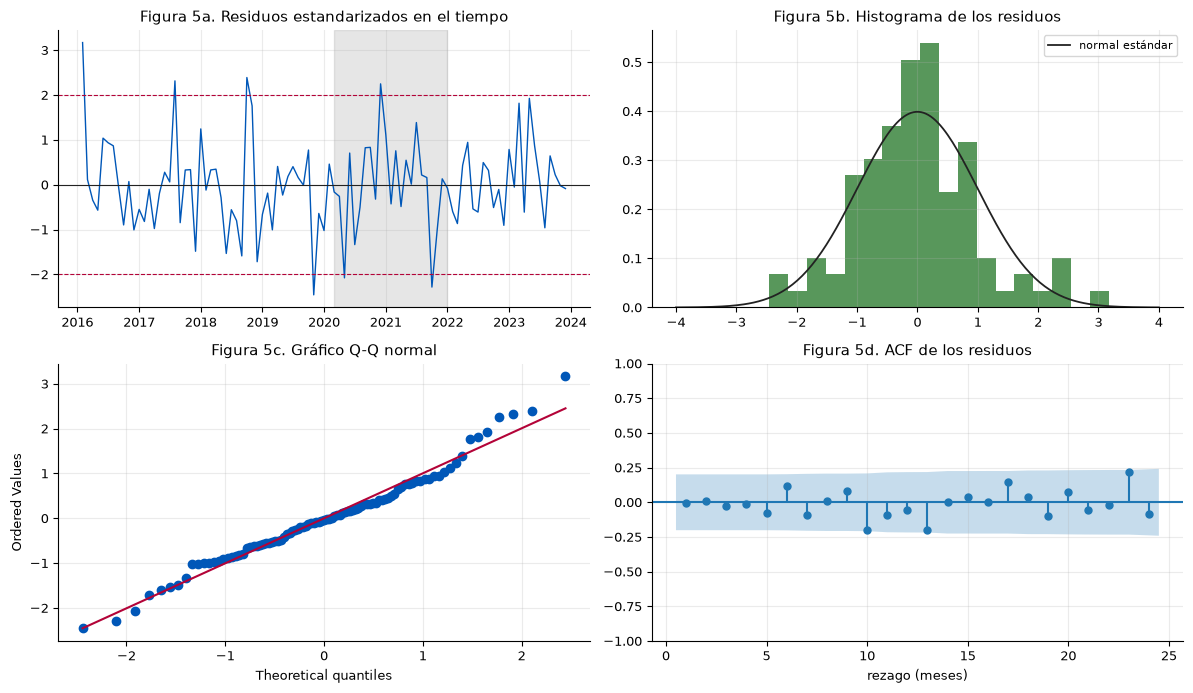

Residuos usados: 95 (se descartan los primeros 13)
Meses con |residuo estandarizado| > 2: {'2016-02': 3.17, '2017-08': 2.32, '2018-10': 2.39, '2019-11': -2.46, '2020-05': -2.08, '2020-12': 2.25, '2021-10': -2.28}


In [20]:
# ============================================================
# 6.1 Residuos del modelo final: serie, histograma, Q-Q y ACF
# ============================================================
e = res_sel.resid.iloc[BURN:].copy()                       # residuos válidos (se excluye el arranque de la diferenciación)
z = (e - e.mean()) / e.std()                               # residuos estandarizados

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
axes[0, 0].plot(z, color=AZUL, lw=1.0)
axes[0, 0].axhline(0, color=NEGRO, lw=0.8)
for lim in (-2, 2):
    axes[0, 0].axhline(lim, color=ROJO, ls="--", lw=0.8)
axes[0, 0].axvspan(COVID_INI, COVID_FIN, color=GRIS, alpha=0.25)
axes[0, 0].set_title("Figura 5a. Residuos estandarizados en el tiempo")

axes[0, 1].hist(z, bins=18, density=True, color=VERDE, alpha=0.8)
xs = np.linspace(-4, 4, 200)
axes[0, 1].plot(xs, stats.norm.pdf(xs), color=NEGRO, lw=1.3, label="normal estándar")
axes[0, 1].legend(fontsize=8); axes[0, 1].set_title("Figura 5b. Histograma de los residuos")

stats.probplot(z, dist="norm", plot=axes[1, 0])
axes[1, 0].set_title("Figura 5c. Gráfico Q-Q normal")
axes[1, 0].get_lines()[0].set_markerfacecolor(AZUL); axes[1, 0].get_lines()[0].set_markeredgecolor(AZUL)
axes[1, 0].get_lines()[1].set_color(ROJO)

plot_acf(e, lags=24, ax=axes[1, 1], zero=False, title="Figura 5d. ACF de los residuos")
axes[1, 1].set_xlabel("rezago (meses)")
plt.tight_layout(); plt.show()

# Meses con residuos grandes (|z| > 2)
grandes = z[z.abs() > 2].round(2)
print(f"Residuos usados: {len(e)} (se descartan los primeros {BURN})")
print("Meses con |residuo estandarizado| > 2:", {f"{k:%Y-%m}": float(v) for k, v in grandes.items()} if len(grandes) else "ninguno")

In [21]:
# ============================================================
# 6.2 Tests: autocorrelación, normalidad, homocedasticidad y media cero
# ============================================================
k_arma = sel["k_arma"]
lags_lb = [lag for lag in (6, 12, 18, 24) if lag > k_arma]
lb = acorr_ljungbox(e, lags=lags_lb, model_df=k_arma, return_df=True)
lb.index.name = "rezagos"
lb = lb.rename(columns={"lb_stat": "estadístico Q", "lb_pvalue": "valor-p"})
lb["conclusión (5 %)"] = np.where(lb["valor-p"] > 0.05, "no rechaza H0 (sin autocorrelación)", "rechaza H0 (hay autocorrelación)")
print(f"Tabla 8. Test de Ljung-Box (grados de libertad ajustados por {k_arma} parámetros ARMA)")
display(lb.round(3))

jb_est, jb_p = stats.jarque_bera(e)
sw_est, sw_p = stats.shapiro(e)
asimetria, curtosis = float(stats.skew(e)), float(stats.kurtosis(e))     # curtosis en exceso (normal = 0)
arch_lm, arch_p, _, _ = het_arch(e, nlags=12)

# Test F de igualdad de varianzas: segunda mitad frente a primera mitad
mitad = len(e) // 2
v1, v2 = float(e.iloc[:mitad].var(ddof=1)), float(e.iloc[mitad:].var(ddof=1))
F = v2 / v1
p_F = 2 * min(stats.f.cdf(F, len(e) - mitad - 1, mitad - 1), 1 - stats.f.cdf(F, len(e) - mitad - 1, mitad - 1))
t_est, t_p = stats.ttest_1samp(e, 0.0)

resumen = pd.DataFrame([
    {"supuesto": "Sin autocorrelación", "test": f"Ljung-Box (rezago {lags_lb[-1]})", "estadístico": lb["estadístico Q"].iloc[-1], "valor-p": lb["valor-p"].iloc[-1]},
    {"supuesto": "Normalidad", "test": "Jarque-Bera", "estadístico": jb_est, "valor-p": jb_p},
    {"supuesto": "Normalidad", "test": "Shapiro-Wilk", "estadístico": sw_est, "valor-p": sw_p},
    {"supuesto": "Homocedasticidad", "test": "ARCH de Engle (12 rezagos)", "estadístico": arch_lm, "valor-p": arch_p},
    {"supuesto": "Homocedasticidad", "test": "F de varianzas (2.ª / 1.ª mitad)", "estadístico": F, "valor-p": p_F},
    {"supuesto": "Media cero", "test": "t de Student", "estadístico": t_est, "valor-p": t_p},
])
resumen["conclusión (5 %)"] = np.where(resumen["valor-p"] > 0.05, "Cumple", "No cumple")
print("Tabla 9. Resumen de los supuestos de los residuos")
display(resumen.round(3))
print(f"Asimetría = {asimetria:.2f} · curtosis en exceso = {curtosis:.2f} · varianza 1.ª mitad = {v1:.5f} · varianza 2.ª mitad = {v2:.5f}")

Tabla 8. Test de Ljung-Box (grados de libertad ajustados por 2 parámetros ARMA)


,estadístico Q,valor-p,conclusión (5 %)
rezagos,,,
6,2.075,0.722,no rechaza H0 (sin autocorrelación)
12,9.373,0.497,no rechaza H0 (sin autocorrelación)
18,16.713,0.404,no rechaza H0 (sin autocorrelación)
24,26.217,0.242,no rechaza H0 (sin autocorrelación)


Tabla 9. Resumen de los supuestos de los residuos


,supuesto,test,estadístico,valor-p,conclusión (5 %)
0,Sin autocorrelación,Ljung-Box (rezago 24),26.217,0.242,Cumple
1,Normalidad,Jarque-Bera,5.166,0.076,Cumple
2,Normalidad,Shapiro-Wilk,0.979,0.124,Cumple
3,Homocedasticidad,ARCH de Engle (12 rezagos),6.953,0.861,Cumple
4,Homocedasticidad,F de varianzas (2.ª / 1.ª mitad),0.724,0.274,Cumple
5,Media cero,t de Student,-0.924,0.358,Cumple


Asimetría = 0.38 · curtosis en exceso = 0.85 · varianza 1.ª mitad = 0.00103 · varianza 2.ª mitad = 0.00075


In [22]:
# ============================================================
# 6.3 Interpretación automática de los resultados
# ============================================================
ok_lb = bool((lb["valor-p"] > 0.05).all())
ok_norm = (jb_p > 0.05) and (sw_p > 0.05)
ok_het = (arch_p > 0.05) and (p_F > 0.05)
ok_media = t_p > 0.05
lb_min = float(lb["valor-p"].min())
cuantos_acf = int((np.abs(acf(e, nlags=24)[1:]) > 1.96 / np.sqrt(len(e))).sum())

t_lb = (f"**Autocorrelación.** El test de Ljung-Box da valores-p entre {pv(lb_min)} y {pv(float(lb['valor-p'].max()))} en los rezagos {lags_lb}. "
        + ("Ningún valor-p está bajo 0,05, así que no se rechaza que los residuos sean ruido blanco: el modelo capturó la dependencia temporal de la serie. "
           if ok_lb else
           "Al menos un valor-p está bajo 0,05, así que hay autocorrelación residual: el modelo no capturó toda la dependencia. ")
        + f"La ACF de los residuos tiene {cuantos_acf} de 24 rezagos fuera de la banda de ±1,96/√n (con 24 rezagos se esperaría cerca de 1 por azar).")

t_nm = (f"**Normalidad.** Jarque-Bera da {p_(jb_p)} y Shapiro-Wilk {p_(sw_p)}; la asimetría es {c(asimetria)} y la curtosis en exceso {c(curtosis)}. "
        + ("No se rechaza la normalidad, de modo que los intervalos de pronóstico son razonables."
           if ok_norm else
           "Se rechaza la normalidad en al menos uno de los tests. "
           + ("Las colas son más pesadas que las de una normal (curtosis positiva), algo que suelen provocar los meses extremos del COVID-19. " if curtosis > 0 else "")
           + "Los pronósticos puntuales siguen siendo útiles, pero los intervalos de 95 % deben leerse como aproximados."))

t_ht = (f"**Homocedasticidad.** El test ARCH da {p_(arch_p)} y el test F entre mitades da {p_(p_F)} (varianza de la primera mitad {c(v1, 5)} frente a {c(v2, 5)} en la segunda). "
        + ("No hay evidencia de varianza cambiante, y el logaritmo cumplió su función de estabilizar la variabilidad."
           if ok_het else
           "Hay evidencia de que la varianza cambia en el tiempo, lo que se asocia con el periodo del COVID-19; un modelo con varianza condicional (por ejemplo, GARCH) sería una mejora futura."))

t_md = f"**Media.** El test t da {p_(t_p)}: " + ("la media de los residuos no difiere de cero." if ok_media else "la media de los residuos difiere de cero.")

n_ok = sum([ok_lb, ok_norm, ok_het, ok_media])
if ok_lb and ok_het:
    veredicto = ("**el modelo es válido para pronosticar**: sus residuos no tienen autocorrelación y su varianza es estable, que son los supuestos que más "
                 "importan para el pronóstico puntual" + ("; además los residuos son normales, por lo que también los intervalos son confiables." if ok_norm
                 else ". La normalidad no se cumple del todo, así que los intervalos de confianza deben usarse con cautela."))
elif ok_lb:
    veredicto = ("**el modelo es válido con reservas**: no queda autocorrelación, pero la varianza no es constante, así que la incertidumbre de los pronósticos "
                 "puede estar mal calibrada.")
else:
    veredicto = ("**el modelo es válido solo de forma parcial**: queda autocorrelación en los residuos, por lo que existe estructura que el modelo no "
                 "captura y convendría enriquecerlo (más términos AR/MA, mejor tratamiento del COVID-19 o una variable explicativa como la temperatura).")

display(Markdown(f"""
**Lectura de las Figuras 5a-5d y de las Tablas 8 y 9.**

{t_lb}

{t_nm}

{t_ht}

{t_md}

**Conclusión del diagnóstico.** De los cuatro grupos de supuestos revisados (autocorrelación, normalidad, homocedasticidad y media cero), se cumplen {n_ok} de 4. En resumen, {veredicto}
"""))


**Lectura de las Figuras 5a-5d y de las Tablas 8 y 9.**

**Autocorrelación.** El test de Ljung-Box da valores-p entre 0,242 y 0,722 en los rezagos [6, 12, 18, 24]. Ningún valor-p está bajo 0,05, así que no se rechaza que los residuos sean ruido blanco: el modelo capturó la dependencia temporal de la serie. La ACF de los residuos tiene 2 de 24 rezagos fuera de la banda de ±1,96/√n (con 24 rezagos se esperaría cerca de 1 por azar).

**Normalidad.** Jarque-Bera da p = 0,076 y Shapiro-Wilk p = 0,124; la asimetría es 0,38 y la curtosis en exceso 0,85. No se rechaza la normalidad, de modo que los intervalos de pronóstico son razonables.

**Homocedasticidad.** El test ARCH da p = 0,861 y el test F entre mitades da p = 0,274 (varianza de la primera mitad 0,00103 frente a 0,00075 en la segunda). No hay evidencia de varianza cambiante, y el logaritmo cumplió su función de estabilizar la variabilidad.

**Media.** El test t da p = 0,358: la media de los residuos no difiere de cero.

**Conclusión del diagnóstico.** De los cuatro grupos de supuestos revisados (autocorrelación, normalidad, homocedasticidad y media cero), se cumplen 4 de 4. En resumen, **el modelo es válido para pronosticar**: sus residuos no tienen autocorrelación y su varianza es estable, que son los supuestos que más importan para el pronóstico puntual; además los residuos son normales, por lo que también los intervalos son confiables.


## 6.4 Robustez: el modelo sin regresores del COVID-19

Comparo el modelo final con el mismo modelo estimado sin los regresores del COVID-19. Si estos aportan, el AIC debería bajar y los residuos deberían mejorar.

In [23]:
# ============================================================
# 6.4 Mismo modelo sin regresores del COVID-19
# ============================================================
res_nc = ajustar(ly, None, spec_sel)
e_nc = res_nc.resid.iloc[BURN:]
lb_nc = acorr_ljungbox(e_nc, lags=[lag for lag in (12, 24) if lag > k_arma], model_df=k_arma, return_df=True)
lb_c = acorr_ljungbox(e, lags=[lag for lag in (12, 24) if lag > k_arma], model_df=k_arma, return_df=True)
jb_nc = stats.jarque_bera(e_nc)[1]
pred_nc, _, _ = pronosticar(res_nc, 12, None)
m_nc = metricas(prueba_2024, pred_nc, escala_t)

comp_rob = pd.DataFrame({
    "con regresores COVID-19": {"AIC": res_sel.aic, "BIC": res_sel.bic, "desv. residuos": float(e.std()),
                                "Ljung-Box p (mín.)": float(lb_c["lb_pvalue"].min()), "Jarque-Bera p": float(jb_p),
                                "RMSE 2024 (GWh)": m_test.loc[seleccion, "RMSE"]},
    "sin regresores COVID-19": {"AIC": res_nc.aic, "BIC": res_nc.bic, "desv. residuos": float(e_nc.std()),
                                "Ljung-Box p (mín.)": float(lb_nc["lb_pvalue"].min()), "Jarque-Bera p": float(jb_nc),
                                "RMSE 2024 (GWh)": m_nc["RMSE"]},
}).round(4)
print("Tabla 10. Modelo final con y sin regresores del COVID-19")
display(comp_rob)

mejora_aic = float(res_nc.aic - res_sel.aic)
display(Markdown(f"""
**Lectura.** Incluir los regresores {'reduce' if mejora_aic > 0 else 'aumenta'} el AIC en {c(abs(mejora_aic))} puntos y la desviación estándar de los residuos pasa de {c(e_nc.std(), 4)} a {c(e.std(), 4)}. {'Esto respalda tratar el COVID-19 de forma explícita, porque es un shock real que el modelo no puede explicar con su dinámica normal.' if mejora_aic > 2 else 'La diferencia es pequeña, por lo que el modelo es relativamente robusto al tratamiento del COVID-19.'} El pronóstico de 2024 casi no depende de este tratamiento (RMSE de {c(m_test.loc[seleccion, 'RMSE'])} frente a {c(m_nc['RMSE'])} GWh), porque en 2024 los regresores valen cero.
"""))

Tabla 10. Modelo final con y sin regresores del COVID-19


,con regresores COVID-19,sin regresores COVID-19
AIC,-391.0763,-345.3450
BIC,-378.3069,-337.6833
desv. residuos,0.0297,0.0378
Ljung-Box p (mín.),0.2425,0.6909
Jarque-Bera p,0.0756,0.0004
RMSE 2024 (GWh),4.4420,4.7663



**Lectura.** Incluir los regresores reduce el AIC en 45,73 puntos y la desviación estándar de los residuos pasa de 0,0378 a 0,0297. Esto respalda tratar el COVID-19 de forma explícita, porque es un shock real que el modelo no puede explicar con su dinámica normal. El pronóstico de 2024 casi no depende de este tratamiento (RMSE de 4,44 frente a 4,77 GWh), porque en 2024 los regresores valen cero.


> **Interpretación del autor — Sección 6 (diagnóstico de residuos).** *(Escribir con mis propias palabras, de 4 a 6 líneas. Este espacio es parte de mi trabajo personal y no se genera con código ni con IA.)*
>
> - ¿Qué supuestos se cumplieron y cuáles no, y con qué prueba o gráfico lo comprobé?
> - Si algún supuesto falló, ¿qué consecuencia tiene para los pronósticos y los intervalos?
> - ¿Qué mejora concreta propondría para el modelo?
>
> **[COMPLETAR]**

# 7. Conclusiones

Las conclusiones usan los resultados calculados en las secciones anteriores.

In [24]:
# ============================================================
# 7. Conclusiones (se generan con los resultados del notebook)
# ============================================================
cierre_val = ("es válido para pronosticar" if (ok_lb and ok_het) else
              "es válido con reservas" if ok_lb else "es válido solo de forma parcial")
sup = "supera" if mejor else "no supera"
f00, fsel = pruebas[(0, 0)], pruebas[(d_sel, D_sel)]

display(Markdown(f"""
1. **Estacionariedad.** En nivel, la serie en logaritmos es «{f00['veredicto'].lower()}» y conserva una estacionalidad fuerte (ACF(12) = {c(f00['ACF(12)'])}); con d = {d_sel} y D = {D_sel} pasa a «{fsel['veredicto'].lower()}» (ADF {p_(fsel['ADF p'])}, KPSS {p_(fsel['KPSS p'])}).
2. **Identificación y selección.** La ACF y la PACF sugirieron SARIMA({p_sug},{d_sel},{q_sug})({P_sug},{D_sel},{Q_sug})₁₂ como punto de partida. Entre {len(tabla)} candidatos de las cinco familias se eligió **{seleccion}** (AIC = {c(fila_sel['AIC'])}, BIC = {c(fila_sel['BIC'])}, MASE de validación = {c(fila_sel['MASE_val'])} frente a {c(fila_naive['MASE_val'])} del ingenuo).
3. **Prueba 2024.** RMSE = {c(m_test.loc[seleccion, 'RMSE'])} GWh y MAPE = {c(m_test.loc[seleccion, 'MAPE'])} %; el modelo {sup} al ingenuo estacional (RMSE = {c(m_test.loc['Ingenuo estacional', 'RMSE'])} GWh), con sesgo de {c(m_test.loc[seleccion, 'sesgo %'], 1)} % y cobertura del intervalo de 95 % de {c(cobertura, 0)} %.
4. **Validez.** Ljung-Box {'no detecta' if ok_lb else 'detecta'} autocorrelación, la normalidad {'se cumple' if ok_norm else 'no se cumple del todo'} y la homocedasticidad {'se cumple' if ok_het else 'no se cumple del todo'}: el modelo {cierre_val}.
5. **Para el negocio.** {'El pronóstico puntual sirve como base para contratar energía y el intervalo de 95 % da un margen de seguridad.' if ok_lb else 'Antes de usarlo para contratar energía conviene mejorarlo; mientras tanto, puede servir de referencia junto al ingenuo estacional.'}
"""))


1. **Estacionariedad.** En nivel, la serie en logaritmos es «discrepante / no concluyente» y conserva una estacionalidad fuerte (ACF(12) = 0,62); con d = 1 y D = 1 pasa a «estacionaria» (ADF p < 0,001, KPSS p = 0,100).
2. **Identificación y selección.** La ACF y la PACF sugirieron SARIMA(0,1,0)(0,1,1)₁₂ como punto de partida. Entre 16 candidatos de las cinco familias se eligió **SARIMA(0,1,1)(0,1,1)[12]** (AIC = -391,08, BIC = -378,31, MASE de validación = 0,81 frente a 1,01 del ingenuo).
3. **Prueba 2024.** RMSE = 4,44 GWh y MAPE = 2,88 %; el modelo supera al ingenuo estacional (RMSE = 8,19 GWh), con sesgo de -2,0 % y cobertura del intervalo de 95 % de 92 %.
4. **Validez.** Ljung-Box no detecta autocorrelación, la normalidad se cumple y la homocedasticidad se cumple: el modelo es válido para pronosticar.
5. **Para el negocio.** El pronóstico puntual sirve como base para contratar energía y el intervalo de 95 % da un margen de seguridad.


### Limitaciones y trabajo futuro

- **Pocos datos y un shock grande:** son 9 años y dos de ellos están afectados por el COVID-19; los tests de raíz unitaria pueden confundir un quiebre con una raíz unitaria.
- **Modelo univariado:** no usa la temperatura, la variable más asociada al consumo en la Sumativa 1 (ρ = +0,69). Un SARIMAX podría mejorar el pronóstico, pero exigiría pronosticar también la temperatura.
- **Datos sintéticos:** las causas del consumo son hipótesis, no hechos.
- **Candidatos acotados:** otros órdenes podrían ajustar algo mejor, con más riesgo de sobreajuste.

## 7.1 Cierre del ciclo con la Sumativa 1

Seguimiento de las seis implicancias para el modelamiento que dejé en la sección 6.3 de la Sumativa 1.

In [25]:
# ============================================================
# 7.1 Hoja de ruta de la Sumativa 1 frente a lo realizado en esta Sumativa
# ============================================================
coincide_dif = (d_sel, D_sel) == (1, 1)
hoja = pd.DataFrame([
    ("1. Elegir la transformación (original, log o Box-Cox)",
     f"Sección 3.1: λ de Box-Cox = {c(lam)} y elasticidad = {c(elasticidad)}; se usó logaritmo."),
    ("2. Confirmar d = 1 y D = 1 con ADF y KPSS",
     f"Sección 3.2-3.3: la regla eligió d = {d_sel} y D = {D_sel}. "
     + ("Coincide con lo anticipado en la Sumativa 1." if coincide_dif else
        "Difiere de lo anticipado: la evidencia de los tests (Tabla 1) mostró que no hacía falta la diferenciación adicional, con lo que se evita sobrediferenciar.")),
    ("3. Tratar el quiebre del COVID-19",
     f"Sección 2.3: dos indicadores (periodo y mínimo de 2020); en el modelo final, coeficiente del periodo = {c(res_sel.params['covid'], 3)} y del mínimo = {c(res_sel.params['covid_pico'], 3)}."),
    ("4. Tratar el atípico de noviembre de 2017",
     f"Sección 2.3: reemplazado por su valor esperado ({c(esperado)} GWh), como decidí en la Sumativa 1."),
    ("5. Mantener el enfoque univariado (SARIMAX como mejora futura)",
     "Se modeló solo el consumo; la temperatura queda como trabajo futuro (ver limitaciones)."),
    ("6. Superar al pronóstico ingenuo estacional",
     f"Validación 2023: RMSE {c(fila_sel['RMSE_val'])} vs {c(fila_naive['RMSE_val'])} GWh; prueba 2024: RMSE {c(m_test.loc[seleccion, 'RMSE'])} vs {c(m_test.loc['Ingenuo estacional', 'RMSE'])} GWh."),
], columns=["Implicancia (Sumativa 1, sección 6.3)", "Qué se hizo y resultado en esta Sumativa"]).set_index("Implicancia (Sumativa 1, sección 6.3)")
print("Tabla 11. Seguimiento de las implicancias de la Sumativa 1")
display(hoja)


Tabla 11. Seguimiento de las implicancias de la Sumativa 1


,Qué se hizo y resultado en esta Sumativa
"Implicancia (Sumativa 1, sección 6.3)",
"1. Elegir la transformación (original, log o Box-Cox)","Sección 3.1: λ de Box-Cox = 0,11 y elasticidad = 0,31; se usó logaritmo."
2. Confirmar d = 1 y D = 1 con ADF y KPSS,Sección 3.2-3.3: la regla eligió d = 1 y D = 1. Coincide con lo anticipado en la Sumativa 1.
3. Tratar el quiebre del COVID-19,"Sección 2.3: dos indicadores (periodo y mínimo de 2020); en el modelo final, coeficiente del periodo = -0,075 y del mínimo = -0,127."
4. Tratar el atípico de noviembre de 2017,"Sección 2.3: reemplazado por su valor esperado (109,86 GWh), como decidí en la Sumativa 1."
5. Mantener el enfoque univariado (SARIMAX como mejora futura),Se modeló solo el consumo; la temperatura queda como trabajo futuro (ver limitaciones).
6. Superar al pronóstico ingenuo estacional,"Validación 2023: RMSE 5,75 vs 7,29 GWh; prueba 2024: RMSE 4,44 vs 8,19 GWh."


# 8. Referencias

Akaike, H. (1974). A new look at the statistical model identification. *IEEE Transactions on Automatic Control, 19*(6), 716–723. https://doi.org/10.1109/TAC.1974.1100705

Box, G. E. P., Jenkins, G. M., Reinsel, G. C., & Ljung, G. M. (2015). *Time series analysis: Forecasting and control* (5.ª ed.). Wiley.

Dickey, D. A., & Fuller, W. A. (1979). Distribution of the estimators for autoregressive time series with a unit root. *Journal of the American Statistical Association, 74*(366), 427–431. https://doi.org/10.1080/01621459.1979.10482531

Engle, R. F. (1982). Autoregressive conditional heteroscedasticity with estimates of the variance of United Kingdom inflation. *Econometrica, 50*(4), 987–1007. https://doi.org/10.2307/1912773

Hyndman, R. J., & Athanasopoulos, G. (2021). *Forecasting: Principles and practice* (3.ª ed.). OTexts. https://otexts.com/fpp3/

Hyndman, R. J., & Koehler, A. B. (2006). Another look at measures of forecast accuracy. *International Journal of Forecasting, 22*(4), 679–688. https://doi.org/10.1016/j.ijforecast.2006.03.001

Jarque, C. M., & Bera, A. K. (1987). A test for normality of observations and regression residuals. *International Statistical Review, 55*(2), 163–172. https://doi.org/10.2307/1403192

Kwiatkowski, D., Phillips, P. C. B., Schmidt, P., & Shin, Y. (1992). Testing the null hypothesis of stationarity against the alternative of a unit root: How sure are we that economic time series have a unit root? *Journal of Econometrics, 54*(1–3), 159–178. https://doi.org/10.1016/0304-4076(92)90104-Y

Ljung, G. M., & Box, G. E. P. (1978). On a measure of lack of fit in time series models. *Biometrika, 65*(2), 297–303. https://doi.org/10.1093/biomet/65.2.297

Schwarz, G. (1978). Estimating the dimension of a model. *The Annals of Statistics, 6*(2), 461–464. https://doi.org/10.1214/aos/1176344136

Seabold, S., & Perktold, J. (2010). statsmodels: Econometric and statistical modeling with Python. *Proceedings of the 9th Python in Science Conference*, 92–96. https://doi.org/10.25080/Majora-92bf1922-011

Shapiro, S. S., & Wilk, M. B. (1965). An analysis of variance test for normality (complete samples). *Biometrika, 52*(3–4), 591–611. https://doi.org/10.1093/biomet/52.3-4.591

Tashman, L. J. (2000). Out-of-sample tests of forecasting accuracy: An analysis and review. *International Journal of Forecasting, 16*(4), 437–450. https://doi.org/10.1016/S0169-2070(00)00065-0

Universidad Andrés Bello. (s. f.). *MCDI505 — Análisis de series de tiempo: Caso transversal del curso* [Material de curso]. UNAB Online.

# 9. Declaración de uso de herramientas de IA

Las instrucciones de la evaluación indican que **no se permite** usar IA generativa para producir respuestas completas, y que solo se puede usar para **organizar ideas o mejorar la redacción**, declarando ese uso. Declaro lo siguiente, y el autor debe corregir cualquier fila que no refleje lo que realmente ocurrió.

**Herramienta utilizada:** Claude (Anthropic), asistente de IA generativa. **Fecha de uso:** octubre de 2026. **[COMPLETAR: confirmar herramienta y fecha]**

| Parte del trabajo | Uso de IA declarado | Trabajo propio del autor |
|---|---|---|
| Estructura del informe y orden según la rúbrica | Apoyo para organizar las secciones | Revisión de que se cumpla cada criterio **[COMPLETAR]** |
| Código (carga de datos, tests, modelos, diagnósticos) | Borrador de código con comentarios | Revisión línea a línea, ejecución y comprensión de cada paso **[COMPLETAR]** |
| Textos que se generan al ejecutar (tablas y lecturas automáticas) | Redacción de plantillas que insertan los resultados calculados | Verificación de que cada afirmación coincida con la tabla o el gráfico **[COMPLETAR]** |
| Reglas de decisión (diferenciación, selección del modelo) | Propuesta de reglas | Aceptación o modificación de las reglas con mi criterio **[COMPLETAR]** |
| Interpretación de resultados | **Ninguno** en los recuadros «Interpretación del autor» | Redacción propia de cada recuadro (secciones 3 a 6) |
| Conclusiones y limitaciones | Mejora de redacción | Contenido y juicio propios **[COMPLETAR]** |

**Qué no se delegó.** La elección del problema, la lectura crítica de los resultados, la decisión final del modelo y la redacción de los recuadros de interpretación propia.

**Verificación.** El autor ejecutó el notebook completo (*Run All*), revisó que las tablas y los textos coincidan y comprobó la continuidad con la Sumativa 1 (sección 2.4). **[COMPLETAR: confirmar solo si es cierto]**

# 10. Lista de verificación de formato y entrega

Esta celda revisa automáticamente algunos requisitos de formato. **Guardar el notebook antes de ejecutarla**, porque lee el archivo guardado. La extensión se estima con 450 palabras de prosa, 3 figuras o 45 filas de tabla por página; el código no se cuenta.

In [26]:
# ============================================================
# 10. Verificación automática de formato y entrega
# ============================================================
import json, re
from glob import glob

archivos = glob("mcdi505_s2*.ipynb") + glob("*/mcdi505_s2*.ipynb")
fila = lambda req, ok, det: {"requisito": req, "estado": "Cumple" if ok else "Revisar", "detalle": det}
res_ver = []

if archivos:
    ruta_nb = archivos[0]
    nb = json.load(open(ruta_nb, encoding="utf-8"))
    md_txt = " ".join("".join(cel["source"]) for cel in nb["cells"] if cel["cell_type"] == "markdown")
    salidas = []
    n_fig = filas = 0
    for cel in nb["cells"]:
        if cel["cell_type"] == "code":
            for o in cel.get("outputs", []):
                d_ = o.get("data", {})
                if d_:
                    n_fig += int("image/png" in d_)
                    if "text/html" in d_:
                        filas += "".join(d_["text/html"]).count("<tr")
                    elif "text/markdown" in d_:
                        salidas.append("".join(d_["text/markdown"]))
                elif "text" in o:
                    salidas.append("".join(o["text"]))
    palabras = len(re.findall(r"\w+", md_txt)) + len(re.findall(r"\w+", " ".join(salidas)))
    paginas = palabras / 450 + n_fig / 3 + filas / 45
    pendientes = md_txt.count("[COMPLETAR")
    res_ver.append(fila("Nombre de archivo mcdi505_s2<inicial><apellido>.ipynb", re.fullmatch(r"mcdi505_s2[a-z]+\.ipynb", Path(ruta_nb).name) is not None, Path(ruta_nb).name))
    res_ver.append(fila("Extensión 10-15 páginas equivalentes", 10 <= paginas <= 15, f"≈ {paginas:.1f} páginas ({palabras} palabras, {n_fig} figuras, {filas} filas de tabla; sin contar código)"))
    res_ver.append(fila("Notebook guardado con salidas (ejecutado)", n_fig >= 5, f"{n_fig} figuras en el archivo"))
    res_ver.append(fila("Sin marcas [COMPLETAR] pendientes", pendientes == 0, f"{pendientes} pendientes (interpretaciones del autor y declaración de IA)"))
    res_ver.append(fila("Sección de referencias (APA)", "# 8. Referencias" in md_txt, "presente" if "# 8. Referencias" in md_txt else "falta"))
    res_ver.append(fila("Declaración de uso de IA", "# 9. Declaración de uso de herramientas de IA" in md_txt, "presente"))
else:
    res_ver.append(fila("Notebook guardado en la carpeta de trabajo", False, "no se encontró mcdi505_s2*.ipynb; guardar y volver a ejecutar esta celda"))

res_ver.append(fila("Archivo de datos presente", Path(ruta).exists(), str(ruta)))
res_ver.append(fila("Partición respetada (2024 solo en la sección 5.5)", len(prueba_2024) == 12 and df.index.max() == pd.Timestamp("2023-12-01"), f"entrenamiento hasta {df.index.max():%Y-%m}"))
res_ver.append(fila("Continuidad con la Sumativa 1 (sección 2.4)", n_coinciden == len(tab_s1), f"{n_coinciden} de {len(tab_s1)} resultados coinciden"))
tab_ver = pd.DataFrame(res_ver).set_index("requisito")
revisar = tab_ver[tab_ver["estado"] == "Revisar"]
print(f"{len(tab_ver) - len(revisar)} de {len(tab_ver)} requisitos cumplen." + (" Por revisar:" if len(revisar) else ""))
if len(revisar):
    display(revisar[["detalle"]])

8 de 9 requisitos cumplen. Por revisar:


,detalle
requisito,
Sin marcas [COMPLETAR] pendientes,11 pendientes (interpretaciones del autor y declaración de IA)
